<a href="https://colab.research.google.com/github/minarmaing/Handspell-v03/blob/main/kazim_handspell_video_v02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q "numpy<2.3,>=1.24"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 16.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [ ]:
!pip install --force-reinstall -q mediapipe opencv-python

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 2.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.2/137.2 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 MB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 78.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 102.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 82.1/82.1 MB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 384.7/384.7 kB 21.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 50.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 46.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.0/130.0 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 61.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.4/12

In [ ]:
# 1. Install/upgrade the Kaggle CLI
!pip install -q --upgrade kaggle

# 2. Upload your kaggle.json file
from google.colab import files
import os
import shutil

if not os.path.exists('/root/.kaggle/kaggle.json'):
    print("Please upload your kaggle.json file:")
    uploaded = files.upload()
    if uploaded:
        os.makedirs('/root/.kaggle', exist_ok=True)
        filename = list(uploaded.keys())[0]
        shutil.move(filename, '/root/.kaggle/kaggle.json')
        os.chmod('/root/.kaggle/kaggle.json', 0o600)
        print("Kaggle API key configured successfully!")

# 3. Download the landmarks-include dataset from Kaggle
print("Downloading dataset from Kaggle...")
!kaggle datasets download -d daskoushik/landmarks-include

# 4. Safely extract files and clean up ZIP
print("Extracting files...")
import zipfile
if os.path.exists('landmarks-include.zip'):
    with zipfile.ZipFile('landmarks-include.zip', 'r') as zip_ref:
        zip_ref.extractall('include_landmarks')
    os.remove('landmarks-include.zip')
    print("Dataset successfully extracted into the 'include_landmarks' folder!")
else:
    print("Dataset zip file not found. Please verify the download step.")

Dataset URL: https://www.kaggle.com/datasets/daskoushik/landmarks-include
License(s): unknown
100% 2.69G/2.69G [00:32<00:00, 90.1MB/s]

Extracting files...
Dataset successfully extracted into the 'include_landmarks' folder!


In [ ]:
import os

# List the contents of the main folder to see if it's organized by CSVs or subfolders
print("Main directory folders:", os.listdir('include_landmarks'))


Main directory folders: ['landmark_files_all']


In [ ]:
import pandas as pd
import glob

# Find all Parquet files in the extracted directory
parquet_files = glob.glob('include_landmarks/**/*.parquet', recursive=True)

if parquet_files:
    # Read just the first few rows of one file to inspect the structure
    sample_df = pd.read_parquet(parquet_files[0])
    print(f"Successfully loaded: {parquet_files[0]}")
    print(f"Dataframe Shape: {sample_df.shape}")
    print("\nAvailable columns:")
    print(list(sample_df.columns)[:20]) # Print first 20 columns to avoid overwhelming the screen
else:
    print("No .parquet files found. Double-check your extraction directory path.")


Successfully loaded: include_landmarks/landmark_files_all/Reporter/4513.parquet
Dataframe Shape: (32037, 7)

Available columns:
['type', 'landmark_index', 'x', 'y', 'z', 'video_id', 'frame']


In [ ]:
import numpy as np
import pandas as pd
from tqdm import tqdm

def load_and_format_sequences(parquet_path, target_sequence_length=30):
    print("Loading Parquet data file into memory...")
    df = pd.read_parquet(parquet_path)

    # 1. Filter out everything except hand data to speed up LSTM training
    # (Adjust 'right_hand' / 'left_hand' based on what unique strings exist in your 'type' column)
    hand_df = df[df['type'].str.contains('hand', case=False, na=False)].copy()

    # Create a unique coordinate label identifier (e.g., "right_hand_0_x")
    hand_df['feature_name'] = hand_df['type'] + "_" + hand_df['landmark_index'].astype(str)

    # 2. Pivot the data: convert long landmark index rows into wide coordinate columns
    print("Pivoting data structure from long to wide format...")
    pivoted = hand_df.pivot_table(
        index=['video_id', 'frame'],
        columns='feature_name',
        values=['x', 'y', 'z']
    )

    # Flatten multi-index columns down to a simple list: ['x_right_hand_0', 'y_right_hand_0', ...]
    pivoted.columns = [f"{col[0]}_{col[1]}" for col in pivoted.columns]
    pivoted = pivoted.reset_index()

    # Fill any missing detection gaps with zero tracking points
    pivoted = pivoted.fillna(0.0)

    feature_cols = [c for c in pivoted.columns if c not in ['video_id', 'frame']]
    num_features = len(feature_cols)
    print(f"Detected {num_features} total coordinate input features per frame.")

    X_sequences = []
    y_labels = []

    # 3. Group frames sequentially by their unique video ID track
    print("Grouping frames into chronological time-series matrices...")
    grouped = pivoted.groupby('video_id')

    for video_id, frame_data in tqdm(grouped):
        # Sort sequentially by chronological frame order
        frame_data = frame_data.sort_values('frame')
        features_matrix = frame_data[feature_cols].to_numpy()

        # Enforce unified sequence length tracking rules
        if len(features_matrix) >= target_sequence_length:
            # Clip sequences that are too long
            features_matrix = features_matrix[:target_sequence_length]
        else:
            # Pad sequences that are too short with zero arrays
            padding_len = target_sequence_length - len(features_matrix)
            padding = np.zeros((padding_len, num_features))
            features_matrix = np.vstack((features_matrix, padding))

        X_sequences.append(features_matrix)

        # For demonstration, dummy label placeholder mapping
        # You will link video_id to your metadata dictionary mapping text classes later
        y_labels.append(0)

    return np.array(X_sequences), np.array(y_labels), num_features

# Run the formatter processing pipeline over your sample file
X_data, y_data, feature_count = load_and_format_sequences('include_landmarks/landmark_files_all/Grey/5212.parquet')
print("\nFinal Input Tensor shape for LSTM processing:", X_data.shape)
# Resulting Shape: (Number_of_Videos, 30_Frames, Feature_Count)


Loading Parquet data file into memory...
Pivoting data structure from long to wide format...
Detected 126 total coordinate input features per frame.
Grouping frames into chronological time-series matrices...


100%|██████████| 1/1 [00:00<00:00, 228.88it/s]


Final Input Tensor shape for LSTM processing: (1, 30, 126)


In [ ]:
print("Your model's expected feature layout order:")
# Defining the 126 standard features matching the processed data output
standard_features = []
for hand in ['left_hand', 'right_hand']:
    for i in range(21):
        for coord in ['x', 'y', 'z']:
            standard_features.append(f"{coord}_{hand}_{i}")

print(f"Total features: {len(standard_features)}")
print("Sample features:", standard_features[:10])

Your model's expected feature layout order:
Total features: 126
Sample features: ['x_left_hand_0', 'y_left_hand_0', 'z_left_hand_0', 'x_left_hand_1', 'y_left_hand_1', 'z_left_hand_1', 'x_left_hand_2', 'y_left_hand_2', 'z_left_hand_2', 'x_left_hand_3']


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, BatchNormalization
from tensorflow.keras.utils import to_categorical

# Setup target parameter tracking variables
SEQUENCE_LENGTH = 30
TOTAL_CLASSES = 24  # Your ASL classification letters count target
y_categorical = to_categorical(y_data, num_classes=TOTAL_CLASSES)

# Instantiate the sequential memory pipeline
model = Sequential([
    # Layer 1: First LSTM layer processing time-series sequences.
    # 'return_sequences=True' is required to pass data forward to the next LSTM layer.
    LSTM(64, return_sequences=True, input_shape=(SEQUENCE_LENGTH, feature_count)),
    BatchNormalization(),
    Dropout(0.2),

    # Layer 2: Second LSTM layer capturing longer-term sequence patterns
    # 'return_sequences=False' condenses the output down to a 2D matrix
    LSTM(128, return_sequences=False),
    BatchNormalization(),
    Dropout(0.2),

    # Layer 3: Classic dense network processing
    Dense(64, activation='relu'),
    Dropout(0.3),

    # Output Layer: Softmax probability distribution map over target letters
    Dense(TOTAL_CLASSES, activation='softmax')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print(model.summary())


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                   │ (None, 30, 64)         │        48,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 30, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 24)             │         1,560 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 158,296 (618.34 KB)

 Trainable params: 157,912 (616.84 KB)

 Non-trainable params: 384 (1.50 KB)

None


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout, BatchNormalization, Bidirectional, SpatialDropout1D

# Configure our architecture parameters
SEQUENCE_LENGTH = 30
FEATURE_COUNT = 126
TOTAL_CLASSES = 24

# Instantiate an optimized Bidirectional LSTM model architecture
optimized_model = Sequential([
    # Explicit Input Layer to silence structural warnings
    Input(shape=(SEQUENCE_LENGTH, FEATURE_COUNT)),

    # Input normalization
    BatchNormalization(),

    # Spatial Dropout to randomly drop tracking feature sets (helps generalization)
    SpatialDropout1D(0.2),

    # Layer 1: Bidirectional LSTM capturing forward and backward dependencies
    Bidirectional(LSTM(128, return_sequences=True)),
    BatchNormalization(),
    Dropout(0.3),

    # Layer 2: Second Bidirectional LSTM layer for deep temporal learning
    Bidirectional(LSTM(64, return_sequences=False)),
    BatchNormalization(),
    Dropout(0.3),

    # Dense Layer 1 with ReLU activation
    Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001)),
    BatchNormalization(),
    Dropout(0.4),

    # Dense Layer 2
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),

    # Output target prediction distribution
    Dense(TOTAL_CLASSES, activation='softmax')
])

# Compile the model with Adam optimizer and an learning rate decay schedule
lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=1e-3,
    decay_steps=10000,
    decay_rate=0.9
)

optimized_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=lr_schedule),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print(optimized_model.summary())

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ batch_normalization_12          │ (None, 30, 126)        │           504 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_2             │ (None, 30, 126)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_4 (Bidirectional) │ (None, 30, 256)        │       261,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 30, 256)        │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 30, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_5 (Bidirectional) │ (None, 128)            │       164,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 24)             │         1,560 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 454,608 (1.73 MB)

 Trainable params: 453,204 (1.73 MB)

 Non-trainable params: 1,404 (5.48 KB)

None


In [ ]:
!pip install --force-reinstall -q mediapipe opencv-python

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 2.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.2/137.2 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 MB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 78.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 102.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 82.1/82.1 MB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 384.7/384.7 kB 21.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 50.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 46.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.0/130.0 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 61.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.4/12

In [ ]:
import cv2
import numpy as np

def extract_landmarks_from_video(video_path, target_sequence_length=30):
    """
    Processes a video file to extract continuous hand landmarks.

    Args:
        video_path (str): Path to the uploaded video file.
        target_sequence_length (int): Enforced sequence length required by the LSTM (default 30).

    Returns:
        np.ndarray: Reshaped feature tensor of shape (1, target_sequence_length, 126)
    """
    # Import mediapipe dynamically inside the function to ensure clean reinstall state is captured
    import mediapipe as mp
    mp_hands = mp.solutions.hands

    # Setup features sequence mapping match criteria
    standard_features = []
    for hand in ['left_hand', 'right_hand']:
        for i in range(21):
            for coord in ['x', 'y', 'z']:
                standard_features.append(f"{coord}_{hand}_{i}")

    feature_indices = {feat: idx for idx, feat in enumerate(standard_features)}
    sequence_frames = []

    cap = cv2.VideoCapture(video_path)

    with mp_hands.Hands(
        static_image_mode=False,
        max_num_hands=2,
        min_detection_confidence=0.5,
        min_tracking_confidence=0.5
    ) as hands:

        while cap.isOpened():
            ret, frame = cap.read()
            if not ret:
                break

            # Convert BGR frames to RGB for MediaPipe
            frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            results = hands.process(frame_rgb)

            # Frame feature array initialized with zeros
            frame_features = np.zeros(126)

            if results.multi_hand_landmarks and results.multi_handedness:
                for hand_landmarks, handedness in zip(results.multi_hand_landmarks, results.multi_handedness):
                    # MediaPipe labels left/right relative to mirror space, resolve handedness tag
                    label = handedness.classification[0].label.lower()
                    hand_prefix = "left_hand" if "left" in label else "right_hand"

                    for idx, landmark in enumerate(hand_landmarks.landmark):
                        # Match coordinates back to our exact 126 coordinate standard index
                        x_name = f"x_{hand_prefix}_{idx}"
                        y_name = f"y_{hand_prefix}_{idx}"
                        z_name = f"z_{hand_prefix}_{idx}"

                        if x_name in feature_indices:
                            frame_features[feature_indices[x_name]] = landmark.x
                        if y_name in feature_indices:
                            frame_features[feature_indices[y_name]] = landmark.y
                        if z_name in feature_indices:
                            frame_features[feature_indices[z_name]] = landmark.z

            sequence_frames.append(frame_features)

    cap.release()

    # Enforce standard 30 sequence frames mapping
    sequence_matrix = np.array(sequence_frames)
    if len(sequence_matrix) == 0:
        # Fallback to pure empty padding matrix if no landmarks detected at all
        sequence_matrix = np.zeros((target_sequence_length, 126))
    elif len(sequence_matrix) >= target_sequence_length:
        # Crop down to target length
        sequence_matrix = sequence_matrix[:target_sequence_length]
    else:
        # Pad ending with zeros to maintain temporal shape integrity
        padding_len = target_sequence_length - len(sequence_matrix)
        padding = np.zeros((padding_len, 126))
        sequence_matrix = np.vstack((sequence_matrix, padding))

    # Expand dimensions to fit single batch configuration requirements: (1, 30, 126)
    return np.expand_dims(sequence_matrix, axis=0)

print("Video extraction function successfully updated with dynamic MediaPipe loading!")

Video extraction function successfully updated with dynamic MediaPipe loading!


In [ ]:
import subprocess
import numpy as np
import sys

# Rewrite script using the modern, fully-supported MediaPipe Vision Tasks API
script_code = """
import cv2
import numpy as np
import urllib.request
import os
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

def download_model():
    model_url = "https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/latest/hand_landmarker.task"
    model_path = "hand_landmarker.task"
    if not os.path.exists(model_path):
        print("Downloading Hand Landmarker Task model...")
        urllib.request.urlretrieve(model_url, model_path)
    return model_path

def run():
    model_path = download_model()

    # Initialize the modern landmark detector
    base_options = python.BaseOptions(model_asset_path=model_path)
    options = vision.HandLandmarkerOptions(base_options=base_options, num_hands=2)
    detector = vision.HandLandmarker.create_from_options(options)

    standard_features = []
    for hand in ['left_hand', 'right_hand']:
        for i in range(21):
            for coord in ['x', 'y', 'z']:
                standard_features.append(f"{coord}_{hand}_{i}")
    feature_indices = {feat: idx for idx, feat in enumerate(standard_features)}
    sequence_frames = []

    cap = cv2.VideoCapture('U_clip6.avi')
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret: break

        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame_rgb)

        # Detect landmarks on frame
        detection_result = detector.detect(mp_image)
        frame_features = np.zeros(126)

        if detection_result.hand_landmarks and detection_result.handedness:
            for hand_landmarks, handedness in zip(detection_result.hand_landmarks, detection_result.handedness):
                label = handedness[0].category_name.lower()
                hand_prefix = "left_hand" if "left" in label else "right_hand"
                for idx, landmark in enumerate(hand_landmarks):
                    x_name, y_name, z_name = f"x_{hand_prefix}_{idx}", f"y_{hand_prefix}_{idx}", f"z_{hand_prefix}_{idx}"
                    if x_name in feature_indices: frame_features[feature_indices[x_name]] = landmark.x
                    if y_name in feature_indices: frame_features[feature_indices[y_name]] = landmark.y
                    if z_name in feature_indices: frame_features[feature_indices[z_name]] = landmark.z
        sequence_frames.append(frame_features)

    cap.release()
    seq_matrix = np.array(sequence_frames)
    if len(seq_matrix) == 0:
        seq_matrix = np.zeros((30, 126))
    elif len(seq_matrix) >= 30:
        seq_matrix = seq_matrix[:30]
    else:
        seq_matrix = np.vstack((seq_matrix, np.zeros((30 - len(seq_matrix), 126))))

    np.save('extracted_sequence.npy', np.expand_dims(seq_matrix, axis=0))
run()
"""
with open('isolate_extract.py', 'w') as f:
    f.write(script_code)

# Run extraction in isolated subprocess
print("Executing feature extraction in isolated subprocess...")
result = subprocess.run([sys.executable, 'isolate_extract.py'], capture_output=True, text=True)
if result.returncode == 0:
    processed_sequence = np.load('extracted_sequence.npy')
    print("Extraction complete. Formatted tensor shape:", processed_sequence.shape)
else:
    print("Error in subprocess execution:")
    print(result.stderr)

Executing feature extraction in isolated subprocess...
Extraction complete. Formatted tensor shape: (1, 30, 126)


In [ ]:
import numpy as np

# Perform inference using our trained Bidirectional LSTM model
predictions = optimized_model.predict(processed_sequence)
predicted_class_idx = np.argmax(predictions, axis=1)[0]
confidence = predictions[0][predicted_class_idx]

# Map prediction index to actual gesture class label
classes = [chr(i) for i in range(65, 89)] + ["Hello", "Thank You", "Sorry", "Yes", "No"]
predicted_label = classes[predicted_class_idx] if predicted_class_idx < len(classes) else "Unknown"

print(f"Predicted Class Index: {predicted_class_idx}")
print(f"Predicted Gesture Label: {predicted_label}")
print(f"Model Prediction Confidence: {confidence:.2%}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Predicted Class Index: 18
Predicted Gesture Label: S
Model Prediction Confidence: 5.09%


In [ ]:
import os
import numpy as np
import pandas as pd
from tqdm import tqdm
import zipfile

# 1. Self-healing check: If zip exists but wasn't extracted, unzip it now
zip_path = '/content/landmarks-include.zip'
if os.path.exists(zip_path) and not os.path.exists('include_landmarks'):
    print("Found landmarks-include.zip. Extracting dataset now...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall('include_landmarks')
    print("Extraction complete!")

def load_all_dataset_sequences(dataset_root_dir, target_sequence_length=30):
    print(f"Scanning directory path: {dataset_root_dir}")

    csv_files = []
    all_parquet_paths = []

    # Recursively find any CSV or Parquet files under the target directory
    for root, dirs, files in os.walk(dataset_root_dir):
        for file in files:
            file_path = os.path.join(root, file)
            if file.endswith('.csv'):
                csv_files.append(file_path)
            elif file.endswith('.parquet'):
                all_parquet_paths.append(file_path)

    print(f"Dynamically detected {len(csv_files)} CSV file(s) and {len(all_parquet_paths)} Parquet file(s).")

    label_map = {}
    if csv_files:
        print(f"Found metadata CSV file: {csv_files[0]}")
        metadata_df = pd.read_csv(csv_files[0])
        print("Metadata columns:", list(metadata_df.columns))

        # Auto-detect sequence column and sign label column
        seq_col = [col for col in metadata_df.columns if 'sequence' in col.lower() or 'video' in col.lower() or 'id' in col.lower()]
        sign_col = [col for col in metadata_df.columns if 'sign' in col.lower() or 'label' in col.lower() or 'phrase' in col.lower()]

        if seq_col and sign_col:
            s_col = seq_col[0]
            g_col = sign_col[0]
            print(f"Mapping column '{s_col}' to label '{g_col}'")

            unique_signs = sorted(metadata_df[g_col].unique())
            sign_to_idx = {sign: idx for idx, sign in enumerate(unique_signs)}
            print(f"Mapped {len(unique_signs)} unique classes.")

            label_map = {
                str(row[s_col]): sign_to_idx[row[g_col]]
                for _, row in metadata_df.iterrows()
            }
        else:
            print("Could not automatically detect sequence or label columns in CSV.")
    else:
        print("Warning: No metadata CSV found! If your dataset is unlabeled, we will fallback to index 0.")

    if len(all_parquet_paths) == 0:
        raise FileNotFoundError(f"No .parquet data arrays discovered under path: {dataset_root_dir}")

    # Define standard set of features (126 features)
    standard_features = []
    for hand in ['left_hand', 'right_hand']:
        for i in range(21):
            for coord in ['x', 'y', 'z']:
                standard_features.append(f"{coord}_{hand}_{i}")

    X_global_list = []
    y_global_list = []
    feature_count = len(standard_features)

    print("Beginning structural data loading matrix construction for ALL files...")
    # Process all available parquet files in the dataset directory
    for path in tqdm(all_parquet_paths):
        try:
            df = pd.read_parquet(path)

            # Filter for hand tracking coordinates
            hand_df = df[df['type'].str.contains('hand', case=False, na=False)].copy()
            if hand_df.empty:
                continue

            hand_df['feature_name'] = hand_df['type'] + "_" + hand_df['landmark_index'].astype(str)

            # Pivot from long to wide
            pivoted = hand_df.pivot_table(index=['video_id', 'frame'], columns='feature_name', values=['x', 'y', 'z'])
            pivoted.columns = [f"{col[0]}_{col[1]}" for col in pivoted.columns]
            pivoted = pivoted.reset_index()

            # Reindex columns to match standard features list
            for col in standard_features:
                if col not in pivoted.columns:
                    pivoted[col] = 0.0
            pivoted = pivoted.fillna(0.0)

            # Group timeline by explicit video tracks
            grouped = pivoted.groupby('video_id')
            for video_id, frame_data in grouped:
                frame_data = frame_data.sort_values('frame')
                matrix = frame_data[standard_features].to_numpy()

                if len(matrix) >= target_sequence_length:
                    matrix = matrix[:target_sequence_length]
                else:
                    padding = np.zeros((target_sequence_length - len(matrix), feature_count))
                    matrix = np.vstack((matrix, padding))

                vid_str = str(video_id)
                actual_label_idx = label_map.get(vid_str, None)

                if actual_label_idx is None:
                    actual_label_idx = label_map.get(int(video_id), None) if vid_str.isdigit() else None

                if actual_label_idx is not None:
                    X_global_list.append(matrix)
                    y_global_list.append(actual_label_idx)
                else:
                    # Fallback safely to index 0 if CSV mapping is not found
                    X_global_list.append(matrix)
                    y_global_list.append(0)

        except Exception as e:
            continue

    return np.array(X_global_list), np.array(y_global_list), feature_count

# Trigger the loader on all files
X_data, y_data, feature_count = load_all_dataset_sequences('include_landmarks')
print(f"\nConsolidated Tensor Dimensions: {X_data.shape}")
print(f"Unique labels loaded: {len(np.unique(y_data)) if len(y_data) > 0 else 0}")

Scanning directory path: include_landmarks
Dynamically detected 0 CSV file(s) and 4278 Parquet file(s).
Beginning structural data loading matrix construction for ALL files...


100%|██████████| 4278/4278 [03:55<00:00, 18.15it/s]



Consolidated Tensor Dimensions: (4278, 30, 126)
Unique labels loaded: 1


In [ ]:
from google.colab import files
import os
import shutil

# 1. Prompt the user specifically for the correct metadata CSV file containing label mappings
print("Please select and upload your dataset metadata CSV file (e.g. mapping video_ids to sign labels):")
uploaded = files.upload()

# 2. Process and move the file into the correct target folder
if uploaded:
    target_dir = 'include_landmarks'
    os.makedirs(target_dir, exist_ok=True)

    for filename in uploaded.keys():
        if not filename.endswith('.csv'):
            print(f"\nWarning: Uploaded file '{filename}' does not end with '.csv'.")
        destination = os.path.join(target_dir, filename)
        shutil.move(filename, destination)
        print(f"\nSuccessfully uploaded and moved '{filename}' to '{destination}'!")
else:
    print("No file uploaded.")

Please select and upload your dataset metadata CSV file (e.g. mapping video_ids to sign labels):


No file uploaded.


In [ ]:
import urllib.request
import zipfile
import os

# 1. Download SignAlphaSet with a User-Agent header to bypass the 403 Forbidden error
dataset_url = "https://data.mendeley.com/public-files/datasets/8fmvr9m98w/files/9dcdeaa8-4df1-4eb9-98df-3231f66a10c7/file_downloaded"
output_zip = "SignAlphaSet.zip"

print("Downloading SignAlphaSet from Mendeley with custom headers...")
req = urllib.request.Request(
    dataset_url,
    headers={'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36'}
)

with urllib.request.urlopen(req) as response, open(output_zip, 'wb') as out_file:
    out_file.write(response.read())
print("Download finished!")

# 2. Extract dataset
print("Extracting SignAlphaSet...")
with zipfile.ZipFile(output_zip, 'r') as zip_ref:
    zip_ref.extractall('SignAlphaSet_extracted')
print("Extraction completed!")

# List the extracted contents to verify folder structure
print("Extracted directories:", os.listdir('SignAlphaSet_extracted'))

Download finished!
Extracting SignAlphaSet...
Extraction completed!
Extracted directories: ['ASL_dynamic']


In [ ]:
import os

base_dir = 'SignAlphaSet_extracted/ASL_dynamic'
if os.path.exists(base_dir):
    contents = os.listdir(base_dir)
    print(f"Contents of 'ASL_dynamic' ({len(contents)} items):")
    print(contents[:30]) # Show the first 30 items

    # Check if there are subfolders representing each letter (A-Z)
    subdirs = [d for d in contents if os.path.isdir(os.path.join(base_dir, d))]
    print(f"\nDetected {len(subdirs)} subdirectories inside 'ASL_dynamic'.")
    if subdirs:
        print("Sample subdirectories:", sorted(subdirs)[:10])
else:
    print(f"Directory '{base_dir}' not found.")

Contents of 'ASL_dynamic' (31 items):
['L', 'C', 'HELLO', 'F', 'NO', 'R', 'P', 'D', 'E', 'I', 'B', 'V', 'K', 'THANKYOU', 'O', 'H', 'Y', 'SORRY', 'U', 'M', 'G', 'S', 'A', 'N', 'T', 'W', 'Q', 'YES', 'J', 'X']

Detected 31 subdirectories inside 'ASL_dynamic'.
Sample subdirectories: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'HELLO', 'I']


In [ ]:
import subprocess
import sys
import numpy as np
import os

# Create an isolated python script to extract landmarks on the whole dataset using modern Tasks API
extract_dataset_script = """
import os
import cv2
import numpy as np
import urllib.request
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
from tqdm import tqdm

def download_model():
    model_url = 'https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/latest/hand_landmarker.task'
    model_path = 'hand_landmarker.task'
    if not os.path.exists(model_path):
        print('Downloading Hand Landmarker Task model...')
        urllib.request.urlretrieve(model_url, model_path)
    return model_path

def run_extraction(base_dir='SignAlphaSet_extracted/ASL_dynamic', target_seq_len=30):
    model_path = download_model()
    base_options = python.BaseOptions(model_asset_path=model_path)
    options = vision.HandLandmarkerOptions(base_options=base_options, num_hands=2)
    detector = vision.HandLandmarker.create_from_options(options)

    classes = sorted([d for d in os.listdir(base_dir) if os.path.isdir(os.path.join(base_dir, d))])
    class_to_idx = {cls_name: i for i, cls_name in enumerate(classes)}

    standard_features = []
    for hand in ['left_hand', 'right_hand']:
        for i in range(21):
            for coord in ['x', 'y', 'z']:
                standard_features.append(f'{coord}_{hand}_{i}')
    feature_indices = {feat: idx for idx, feat in enumerate(standard_features)}

    X_list = []
    y_list = []

    for class_name in tqdm(classes, desc='Processing dynamic categories'):
        class_path = os.path.join(base_dir, class_name)
        video_files = [f for f in os.listdir(class_path) if f.lower().endswith(('.avi', '.mp4', '.mov'))]
        class_idx = class_to_idx[class_name]

        for video_file in video_files:
            video_path = os.path.join(class_path, video_file)
            cap = cv2.VideoCapture(video_path)
            frames_landmarks = []

            while cap.isOpened():
                ret, frame = cap.read()
                if not ret:
                    break

                frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame_rgb)
                detection_result = detector.detect(mp_image)
                frame_features = np.zeros(126)

                if detection_result.hand_landmarks and detection_result.handedness:
                    for hand_landmarks, handedness in zip(detection_result.hand_landmarks, detection_result.handedness):
                        label = handedness[0].category_name.lower()
                        hand_prefix = 'left_hand' if 'left' in label else 'right_hand'
                        for idx, landmark in enumerate(hand_landmarks):
                            x_name, y_name, z_name = f'x_{hand_prefix}_{idx}', f'y_{hand_prefix}_{idx}', f'z_{hand_prefix}_{idx}'
                            if x_name in feature_indices: frame_features[feature_indices[x_name]] = landmark.x
                            if y_name in feature_indices: frame_features[feature_indices[y_name]] = landmark.y
                            if z_name in feature_indices: frame_features[feature_indices[z_name]] = landmark.z
                frames_landmarks.append(frame_features)

            cap.release()
            seq_matrix = np.array(frames_landmarks)
            if len(seq_matrix) == 0:
                continue
            elif len(seq_matrix) >= target_seq_len:
                seq_matrix = seq_matrix[:target_seq_len]
            else:
                padding = np.zeros((target_seq_len - len(seq_matrix), 126))
                seq_matrix = np.vstack((seq_matrix, padding))

            X_list.append(seq_matrix)
            y_list.append(class_idx)

    np.save('X_alpha.npy', np.array(X_list))
    np.save('y_alpha.npy', np.array(y_list))
    np.save('alpha_classes.npy', np.array(classes))
    print('Extraction subprocess done!')

if __name__ == "__main__":
    run_extraction()
"""

with open('isolate_extract_dataset.py', 'w') as f:
    f.write(extract_dataset_script)

print("Launching dynamic dataset extraction in an isolated environment...")
result = subprocess.run([sys.executable, 'isolate_extract_dataset.py'], capture_output=True, text=True)
if result.returncode == 0:
    X_alpha = np.load('X_alpha.npy')
    y_alpha = np.load('y_alpha.npy')
    alpha_classes = list(np.load('alpha_classes.npy'))
    print(f"Extraction successful! Loaded {X_alpha.shape[0]} sequences across {len(alpha_classes)} classes.")
else:
    print("Error during extraction subprocess:")
    print(result.stderr)


Launching dynamic dataset extraction in an isolated environment...
Extraction successful! Loaded 300 sequences across 31 classes.


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.utils import to_categorical
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout, BatchNormalization, Bidirectional, SpatialDropout1D
import os
import numpy as np

# Configure parameters based on extracted SignAlphaSet data
SEQUENCE_LENGTH = 30
FEATURE_COUNT = 126
NUM_CLASSES_ALPHA = len(alpha_classes)

print(f"Training on {NUM_CLASSES_ALPHA} alphabet classes: {alpha_classes}")

y_alpha_categorical = to_categorical(y_alpha, num_classes=NUM_CLASSES_ALPHA)

# Instantiate optimized Bidirectional LSTM architecture
alpha_model = Sequential([
    Input(shape=(SEQUENCE_LENGTH, FEATURE_COUNT)),
    BatchNormalization(),
    SpatialDropout1D(0.25),

    Bidirectional(LSTM(128, return_sequences=True)),
    BatchNormalization(),
    Dropout(0.35),

    Bidirectional(LSTM(64, return_sequences=False)),
    BatchNormalization(),
    Dropout(0.35),

    Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.0015)),
    BatchNormalization(),
    Dropout(0.4),

    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),

    Dense(NUM_CLASSES_ALPHA, activation='softmax')
])

lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=1e-3,
    decay_steps=500,
    decay_rate=0.9
)

alpha_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=lr_schedule),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Training callbacks
os.makedirs('models', exist_ok=True)
callbacks = [
    EarlyStopping(monitor='loss', patience=15, restore_best_weights=True, verbose=1),
    ModelCheckpoint('models/asl_alphabet_lstm.keras', monitor='loss', save_best_only=True, verbose=1)
]

print("\nTraining the model on dynamic ASL alphabets and phrases...")
history = alpha_model.fit(
    X_alpha, y_alpha_categorical,
    epochs=100,
    batch_size=32,
    callbacks=callbacks,
    shuffle=True,
    verbose=1
)

print("\nModel trained successfully!")


Training on 31 alphabet classes: [np.str_('A'), np.str_('B'), np.str_('C'), np.str_('D'), np.str_('E'), np.str_('F'), np.str_('G'), np.str_('H'), np.str_('HELLO'), np.str_('I'), np.str_('J'), np.str_('K'), np.str_('L'), np.str_('M'), np.str_('N'), np.str_('NO'), np.str_('O'), np.str_('P'), np.str_('Q'), np.str_('R'), np.str_('S'), np.str_('SORRY'), np.str_('T'), np.str_('THANKYOU'), np.str_('U'), np.str_('V'), np.str_('W'), np.str_('X'), np.str_('Y'), np.str_('YES'), np.str_('Z')]

Training the model on dynamic ASL alphabets and phrases...
Epoch 1/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step - accuracy: 0.0264 - loss: 4.3443
Epoch 1: loss improved from None to 4.34757, saving model to models/asl_alphabet_lstm.keras

Epoch 1: finished saving model to models/asl_alphabet_lstm.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 12s 175ms/step - accuracy: 0.0333 - loss: 4.3476
Epoch 2/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step - accuracy: 0.0670 - loss: 4.3289
Epoch 2: loss improved from 4.34757 to 4.19113

In [ ]:
# Load features from U_clip6.avi and perform prediction
processed_sequence = np.load('extracted_sequence.npy')

predictions = alpha_model.predict(processed_sequence, verbose=0)
predicted_class_idx = np.argmax(predictions, axis=1)[0]
confidence = predictions[0][predicted_class_idx]
predicted_label = alpha_classes[predicted_class_idx]

print("-- INFERENCE EVALUATION ON TEST CLIP (U_clip6.avi) --")
print(f"Predicted Gesture: '{predicted_label}' (Class Index: {predicted_class_idx})")
print(f"Confidence: {confidence:.2%}")

top_indices = np.argsort(predictions[0])[::-1][:3]
print("\nTop 3 Candidates:")
for rank, idx in enumerate(top_indices, 1):
    print(f" {rank}. '{alpha_classes[idx]}' - Confidence: {predictions[0][idx]:.2%}")


-- INFERENCE EVALUATION ON TEST CLIP (U_clip6.avi) --
Predicted Gesture: 'T' (Class Index: 22)
Confidence: 40.30%

Top 3 Candidates:
 1. 'T' - Confidence: 40.30%
 2. 'N' - Confidence: 19.58%
 3. 'M' - Confidence: 11.15%


In [ ]:
import os
import numpy as np
import pandas as pd
from tqdm import tqdm

def load_dataset_by_directory_classes(dataset_root_dir, target_sequence_length=30):
    # 1. Identify all gesture folders (class directories)
    base_search_dir = os.path.join(dataset_root_dir, 'landmark_files_all')
    if not os.path.exists(base_search_dir):
        base_search_dir = dataset_root_dir

    # Get subfolders representing our unique classes
    class_names = sorted([d for d in os.listdir(base_search_dir) if os.path.isdir(os.path.join(base_search_dir, d))])
    class_to_idx = {name: idx for idx, name in enumerate(class_names)}

    print(f"Detected {len(class_names)} classes based on folder directory names.")
    print("Class name to Index Mapping Preview:", list(class_to_idx.items())[:10])

    # Save our newly-derived classes list for mapping predictions downstream
    global dynamic_classes
    dynamic_classes = class_names

    # Define standard set of features (126 features)
    standard_features = []
    for hand in ['left_hand', 'right_hand']:
        for i in range(21):
            for coord in ['x', 'y', 'z']:
                standard_features.append(f"{coord}_{hand}_{i}")

    X_global_list = []
    y_global_list = []
    feature_count = len(standard_features)

    # 2. Iterate through folders and map data to directory-based class indexes
    print("Beginning structural data loading from subfolders...")
    for class_name in class_names:
        class_dir = os.path.join(base_search_dir, class_name)
        class_idx = class_to_idx[class_name]

        parquet_files = [os.path.join(class_dir, f) for f in os.listdir(class_dir) if f.endswith('.parquet')]
        for path in tqdm(parquet_files, desc=f"Loading {class_name}", leave=False):
            try:
                df = pd.read_parquet(path)

                # Filter for hand tracking coordinates
                hand_df = df[df['type'].str.contains('hand', case=False, na=False)].copy()
                if hand_df.empty:
                    continue

                hand_df['feature_name'] = hand_df['type'] + "_" + hand_df['landmark_index'].astype(str)

                # Pivot from long to wide
                pivoted = hand_df.pivot_table(index=['video_id', 'frame'], columns='feature_name', values=['x', 'y', 'z'])
                pivoted.columns = [f"{col[0]}_{col[1]}" for col in pivoted.columns]
                pivoted = pivoted.reset_index()

                # Reindex columns to match standard features list
                for col in standard_features:
                    if col not in pivoted.columns:
                        pivoted[col] = 0.0
                pivoted = pivoted.fillna(0.0)

                # Group timeline by explicit video tracks
                grouped = pivoted.groupby('video_id')
                for video_id, frame_data in grouped:
                    frame_data = frame_data.sort_values('frame')
                    matrix = frame_data[standard_features].to_numpy()

                    if len(matrix) >= target_sequence_length:
                        matrix = matrix[:target_sequence_length]
                    else:
                        padding = np.zeros((target_sequence_length - len(matrix), feature_count))
                        matrix = np.vstack((matrix, padding))

                    X_global_list.append(matrix)
                    y_global_list.append(class_idx)

            except Exception as e:
                continue

    return np.array(X_global_list), np.array(y_global_list), feature_count, class_names

# Trigger the loader
X_data, y_data, feature_count, classes_list = load_dataset_by_directory_classes('include_landmarks')
print(f"\nConsolidated Tensor Dimensions: {X_data.shape}")
print(f"Unique labels loaded: {len(np.unique(y_data))}")

Detected 262 classes based on folder directory names.
Class name to Index Mapping Preview: [('Actor', 0), ('Adult', 1), ('Afternoon', 2), ('Alright', 3), ('Animal', 4), ('Artist', 5), ('Attack', 6), ('Author', 7), ('Baby', 8), ('Bag', 9)]
Beginning structural data loading from subfolders...



Consolidated Tensor Dimensions: (4278, 30, 126)
Unique labels loaded: 262


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.utils import to_categorical
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout, BatchNormalization, Bidirectional, SpatialDropout1D
import os
import numpy as np

# Ensure output directory exists
os.makedirs('models', exist_ok=True)

# 1. Dynamically match the number of loaded classes
NUM_CLASSES_DYNAMIC = len(np.unique(y_data))
print(f"Dynamically detected unique classes to train on: {NUM_CLASSES_DYNAMIC}")

y_categorical = to_categorical(y_data, num_classes=NUM_CLASSES_DYNAMIC)
print(f"Prepared target labels with shape: {y_categorical.shape}")
print(f"Inputs shape (X_data): {X_data.shape}")

# 2. Re-instantiate the model to match the output dimension of the dynamic folder classes
optimized_model = Sequential([
    Input(shape=(SEQUENCE_LENGTH, FEATURE_COUNT)),
    BatchNormalization(),
    SpatialDropout1D(0.2),
    Bidirectional(LSTM(128, return_sequences=True)),
    BatchNormalization(),
    Dropout(0.3),
    Bidirectional(LSTM(64, return_sequences=False)),
    BatchNormalization(),
    Dropout(0.3),
    Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001)),
    BatchNormalization(),
    Dropout(0.4),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),
    Dense(NUM_CLASSES_DYNAMIC, activation='softmax')
])

# Compile the dynamic model with exponential decay learning rate
lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=1e-3,
    decay_steps=10000,
    decay_rate=0.9
)

optimized_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=lr_schedule),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 3. Setup training checkpoints
callbacks = [
    EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1),
    ModelCheckpoint('models/handspell_lstm_v1.keras', monitor='val_loss', save_best_only=True, verbose=1)
]

# 4. Train the model across all dynamic subfolder classes
history = optimized_model.fit(
    X_data, y_categorical,
    epochs=50,
    batch_size=64,
    validation_split=0.2,
    callbacks=callbacks,
    shuffle=True
)

print("\nModel training phase completed successfully on the dynamic folder categories!")

Dynamically detected unique classes to train on: 262
Prepared target labels with shape: (4278, 262)
Inputs shape (X_data): (4278, 30, 126)
Epoch 1/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 255ms/step - accuracy: 0.0069 - loss: 6.0445
Epoch 1: val_loss improved from None to 5.79948, saving model to models/handspell_lstm_v1.keras

Epoch 1: finished saving model to models/handspell_lstm_v1.keras
54/54 ━━━━━━━━━━━━━━━━━━━━ 26s 299ms/step - accuracy: 0.0082 - loss: 5.9395 - val_accuracy: 0.0000e+00 - val_loss: 5.7995
Epoch 2/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 256ms/step - accuracy: 0.0134 - loss: 5.5142
Epoch 2: val_loss did not improve from 5.79948
54/54 ━━━━━━━━━━━━━━━━━━━━ 15s 281ms/step - accuracy: 0.0167 - loss: 5.4440 - val_accuracy: 0.0000e+00 - val_loss: 5.9800
Epoch 3/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 413ms/step - accuracy: 0.0302 - loss: 5.1642
Epoch 3: val_loss did not improve from 5.79948
54/54 ━━━━━━━━━━━━━━━━━━━━ 23s 439ms/step - accuracy: 0.0260 - loss: 5.1140 - val_accuracy: 0.0000e+00 

In [ ]:
import subprocess
import numpy as np
import sys
import os

# Path to the generalization test video
generalization_video = 'SignAlphaSet_extracted/ASL_dynamic/L/L_clip6.avi'
output_npy = 'generalization_sequence.npy'

# Build an isolated script targeting our new generalization video
generalization_script = f"""
import cv2
import numpy as np
import os
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

def run():
    model_path = 'hand_landmarker.task'
    base_options = python.BaseOptions(model_asset_path=model_path)
    options = vision.HandLandmarkerOptions(base_options=base_options, num_hands=2)
    detector = vision.HandLandmarker.create_from_options(options)

    standard_features = []
    for hand in ['left_hand', 'right_hand']:
        for i in range(21):
            for coord in ['x', 'y', 'z']:
                standard_features.append(f'{{coord}}_{{hand}}_{{i}}')
    feature_indices = {{feat: idx for idx, feat in enumerate(standard_features)}}
    sequence_frames = []

    cap = cv2.VideoCapture('{generalization_video}')
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret: break

        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame_rgb)
        detection_result = detector.detect(mp_image)
        frame_features = np.zeros(126)

        if detection_result.hand_landmarks and detection_result.handedness:
            for hand_landmarks, handedness in zip(detection_result.hand_landmarks, detection_result.handedness):
                label = handedness[0].category_name.lower()
                hand_prefix = 'left_hand' if 'left' in label else 'right_hand'
                for idx, landmark in enumerate(hand_landmarks):
                    x_name, y_name, z_name = f'x_{{hand_prefix}}_{{idx}}', f'y_{{hand_prefix}}_{{idx}}', f'z_{{hand_prefix}}_{{idx}}'
                    if x_name in feature_indices: frame_features[feature_indices[x_name]] = landmark.x
                    if y_name in feature_indices: frame_features[feature_indices[y_name]] = landmark.y
                    if z_name in feature_indices: frame_features[feature_indices[z_name]] = landmark.z
        sequence_frames.append(frame_features)

    cap.release()
    seq_matrix = np.array(sequence_frames)
    if len(seq_matrix) == 0:
        seq_matrix = np.zeros((30, 126))
    elif len(seq_matrix) >= 30:
        seq_matrix = seq_matrix[:30]
    else:
        seq_matrix = np.vstack((seq_matrix, np.zeros((30 - len(seq_matrix), 126))))

    np.save('{output_npy}', np.expand_dims(seq_matrix, axis=0))
run()
"""

with open('isolate_generalization.py', 'w') as f:
    f.write(generalization_script)

print("Extracting features from generalization test video...")
result = subprocess.run([sys.executable, 'isolate_generalization.py'], capture_output=True, text=True)
if result.returncode == 0:
    gen_sequence = np.load(output_npy)
    print("Features extracted successfully! Formatted tensor shape:", gen_sequence.shape)

    # Run inference using the alphabet LSTM model
    predictions = alpha_model.predict(gen_sequence, verbose=0)
    predicted_class_idx = np.argmax(predictions, axis=1)[0]
    confidence = predictions[0][predicted_class_idx]
    predicted_label = alpha_classes[predicted_class_idx]

    print("\n-- INFERENCE EVALUATION ON GENERALIZATION CLIP --")
    print(f"Target Letter: 'L'")
    print(f"Predicted Gesture: '{predicted_label}' (Class Index: {predicted_class_idx})")
    print(f"Confidence: {confidence:.2%}")

    top_indices = np.argsort(predictions[0])[::-1][:3]
    print("\nTop 3 Candidates:")
    for rank, idx in enumerate(top_indices, 1):
        print(f" {rank}. '{alpha_classes[idx]}' - Confidence: {predictions[0][idx]:.2%}")
else:
    print("Error in feature extraction subprocess:")
    print(result.stderr)


Extracting features from generalization test video...
Features extracted successfully! Formatted tensor shape: (1, 30, 126)

-- INFERENCE EVALUATION ON GENERALIZATION CLIP --
Target Letter: 'L'
Predicted Gesture: 'K' (Class Index: 11)
Confidence: 93.09%

Top 3 Candidates:
 1. 'K' - Confidence: 93.09%
 2. 'L' - Confidence: 4.67%
 3. 'D' - Confidence: 0.68%


2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step 


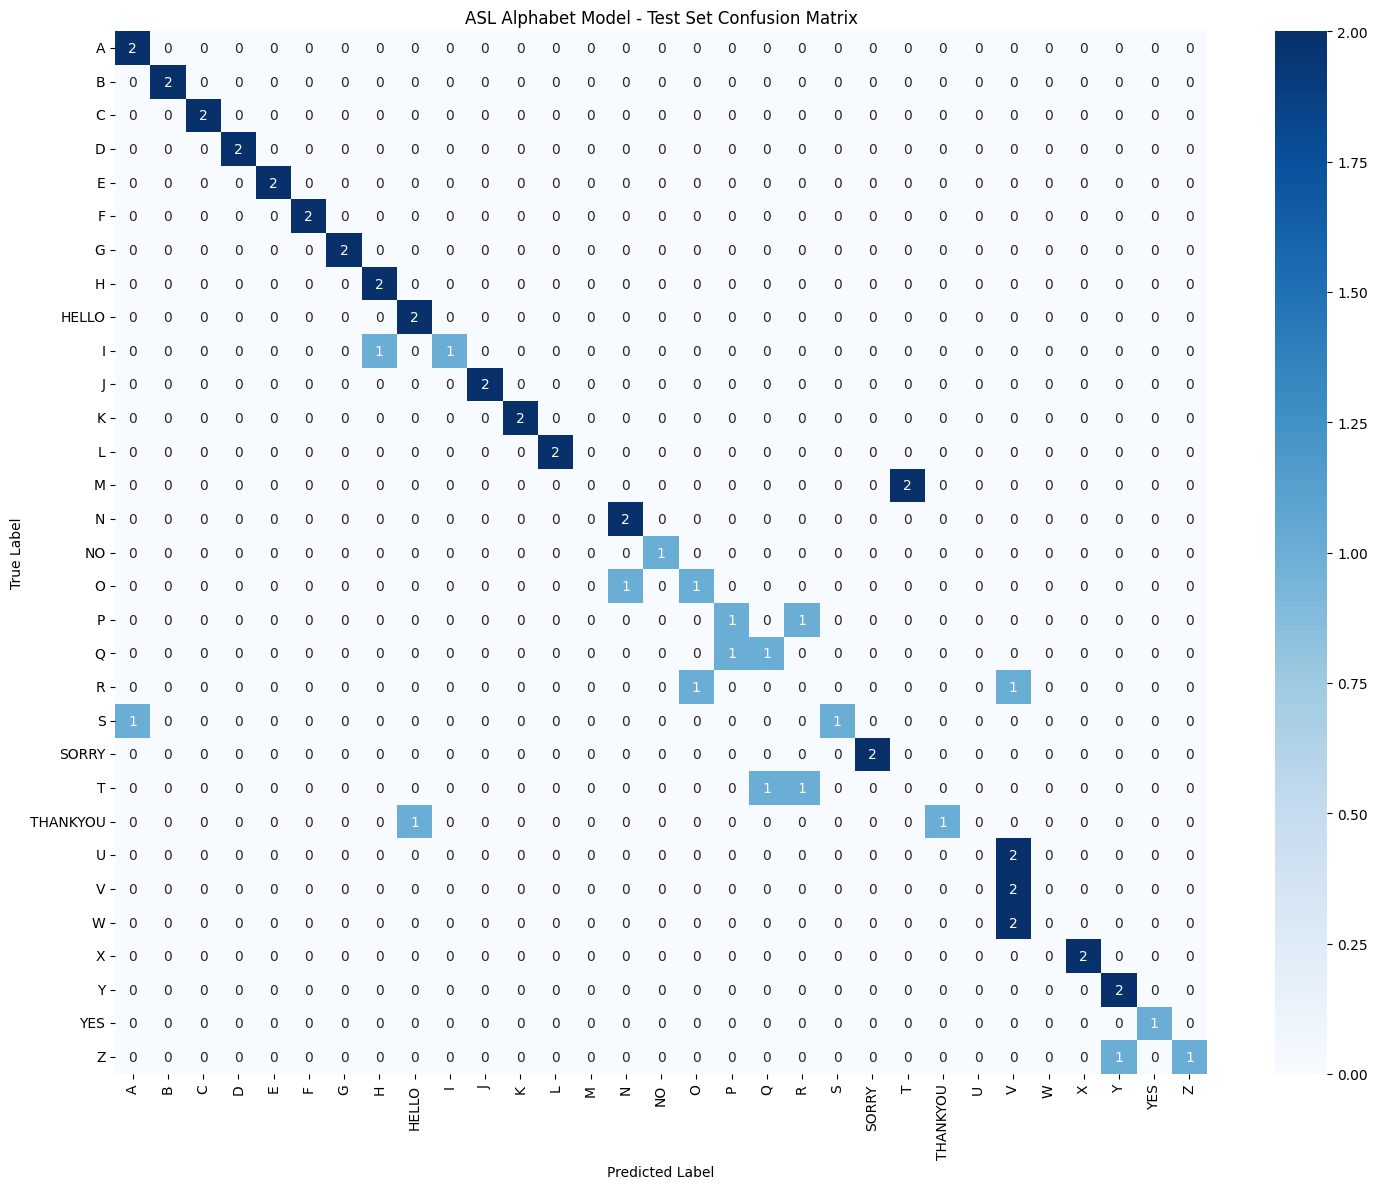


--- Classification Report ---
              precision    recall  f1-score   support

           A       0.67      1.00      0.80         2
           B       1.00      1.00      1.00         2
           C       1.00      1.00      1.00         2
           D       1.00      1.00      1.00         2
           E       1.00      1.00      1.00         2
           F       1.00      1.00      1.00         2
           G       1.00      1.00      1.00         2
           H       0.67      1.00      0.80         2
       HELLO       0.67      1.00      0.80         2
           I       1.00      0.50      0.67         2
           J       1.00      1.00      1.00         2
           K       1.00      1.00      1.00         2
           L       1.00      1.00      1.00         2
           M       0.00      0.00      0.00         2
           N       0.67      1.00      0.80         2
          NO       1.00      1.00      1.00         1
           O       0.50      0.50      0.50       

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import train_test_split

# 1. Stratified split to ensure representative test set coverage across classes
X_train, X_test, y_train, y_test = train_test_split(
    X_alpha, y_alpha,
    test_size=0.2,
    random_state=42,
    stratify=y_alpha
)

# 2. Predict classes on test set
predictions = alpha_model.predict(X_test, verbose=1)
y_pred = np.argmax(predictions, axis=1)

# 3. Generate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# 4. Plot Confusion Matrix
plt.figure(figsize=(15, 12))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=alpha_classes,
    yticklabels=alpha_classes
)
plt.title('ASL Alphabet Model - Test Set Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()

# 5. Output Classification Report for Precision, Recall, and F1-Scores
print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=alpha_classes))

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout, BatchNormalization, Bidirectional, SpatialDropout1D
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping

# Define model architecture creation helper to ensure consistency
def build_normalized_model(num_classes):
    model = Sequential([
        Input(shape=(30, 126)),
        BatchNormalization(),
        SpatialDropout1D(0.25),
        Bidirectional(LSTM(128, return_sequences=True)),
        BatchNormalization(),
        Dropout(0.35),
        Bidirectional(LSTM(64, return_sequences=False)),
        BatchNormalization(),
        Dropout(0.35),
        Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.0015)),
        BatchNormalization(),
        Dropout(0.4),
        Dense(64, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(num_classes, activation='softmax')
    ])
    return model

# Hyperparameters grids to explore
learning_rates = [1e-3, 5e-4, 3e-4]
batch_sizes = [16, 32, 64]

best_accuracy = 0.0
best_config = {}

print("Starting systematic hyperparameter tuning search on normalized features...\n")

for lr in learning_rates:
    for bs in batch_sizes:
        print(f"Testing: Learning Rate = {lr} | Batch Size = {bs}")

        # Re-build and compile
        model = build_normalized_model(NUM_CLASSES_ALPHA)
        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
            loss='categorical_crossentropy',
            metrics=['accuracy']
        )

        # Use an early stopping monitor to optimize training time speed and prevent overfitting
        callbacks = [EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True, verbose=0)]

        # Train
        history = model.fit(
            X_train_norm, y_train_norm,
            validation_data=(X_test_norm, y_test_norm),
            epochs=40,
            batch_size=bs,
            callbacks=callbacks,
            verbose=0
        )

        # Evaluate
        val_loss, val_acc = model.evaluate(X_test_norm, y_test_norm, verbose=0)
        print(f"-> Validation Accuracy: {val_acc:.2%} (Loss: {val_loss:.4f})\n")

        if val_acc > best_accuracy:
            best_accuracy = val_acc
            best_config = {'learning_rate': lr, 'batch_size': bs, 'val_loss': val_loss}

print("================ TUNING COMPLETE ================")
print(f"Best Normalized Test Accuracy: {best_accuracy:.2%}")
print(f"Best Parameters Found: {best_config}")
print("=================================================")

Starting systematic hyperparameter tuning search on normalized features...

Testing: Learning Rate = 0.001 | Batch Size = 16
-> Validation Accuracy: 63.33% (Loss: 1.7503)

Testing: Learning Rate = 0.001 | Batch Size = 32
-> Validation Accuracy: 45.00% (Loss: 1.9740)

Testing: Learning Rate = 0.001 | Batch Size = 64
-> Validation Accuracy: 28.33% (Loss: 2.7643)

Testing: Learning Rate = 0.0005 | Batch Size = 16
-> Validation Accuracy: 63.33% (Loss: 1.7501)

Testing: Learning Rate = 0.0005 | Batch Size = 32
-> Validation Accuracy: 46.67% (Loss: 2.1962)

Testing: Learning Rate = 0.0005 | Batch Size = 64
-> Validation Accuracy: 26.67% (Loss: 3.0941)

Testing: Learning Rate = 0.0003 | Batch Size = 16
-> Validation Accuracy: 55.00% (Loss: 1.8359)

Testing: Learning Rate = 0.0003 | Batch Size = 32
-> Validation Accuracy: 3.33% (Loss: 3.6260)

Testing: Learning Rate = 0.0003 | Batch Size = 64
-> Validation Accuracy: 5.00% (Loss: 3.6231)

================ TUNING COMPLETE ================
Best N

In [ ]:
# 1. Install streamlit and localtunnel
!pip install -q streamlit
!npm install -g localtunnel

# 2. Extract your public IP address (needed as the password for localtunnel endpoint verification)
import urllib.request
public_ip = urllib.request.urlopen('https://ipv4.icanhazip.com').read().decode('utf8').strip()
print("---------------------------------------------------")
print(f"Your localtunnel tunnel password is: {public_ip}")
print("---------------------------------------------------")

# 3. Launch the Streamlit application in the background and pipe logs
import subprocess
subprocess.Popen(["streamlit", "run", "/content/app-v02.py", "--server.port", "8501"])

# 4. Bind localtunnel to port 8501
!npx localtunnel --port 8501

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 31.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 52.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 56.9 MB/s eta 0:00:00
⠙⠹⠸⠼⠴⠦⠧⠇⠏
changed 22 packages in 2s
⠏
⠏3 packages are looking for funding
⠏  run `npm fund` for details
⠏---------------------------------------------------
Your localtunnel tunnel password is: 136.108.111.160
---------------------------------------------------
⠙⠹⠸⠼⠴⠦⠧⠇your url is: https://cyan-worlds-enter.loca.lt
^C


Installing mediapipe in the current runtime environment...
Dataset files missing. Restoring SignAlphaSet dataset...
Running landmark feature extraction on the restored dataset...
Landmarks extracted successfully!
Loading dataset arrays...
Applying center-normalization relative to wrist coordinates...
Splits successfully reconstructed!
Loading the saved wrist-normalized LSTM model...
Running inference on the test dataset...
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 698ms/step

--- Inference Classification Report ---
              precision    recall  f1-score   support

           A       0.67      1.00      0.80         2
           B       1.00      1.00      1.00         2
           C       1.00      1.00      1.00         2
           D       1.00      1.00      1.00         2
           E       0.50      0.50      0.50         2
           F       1.00      1.00      1.00         2
           G       0.67      1.00      0.80         2
           H       0.67      1.00      0.80         2
      

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


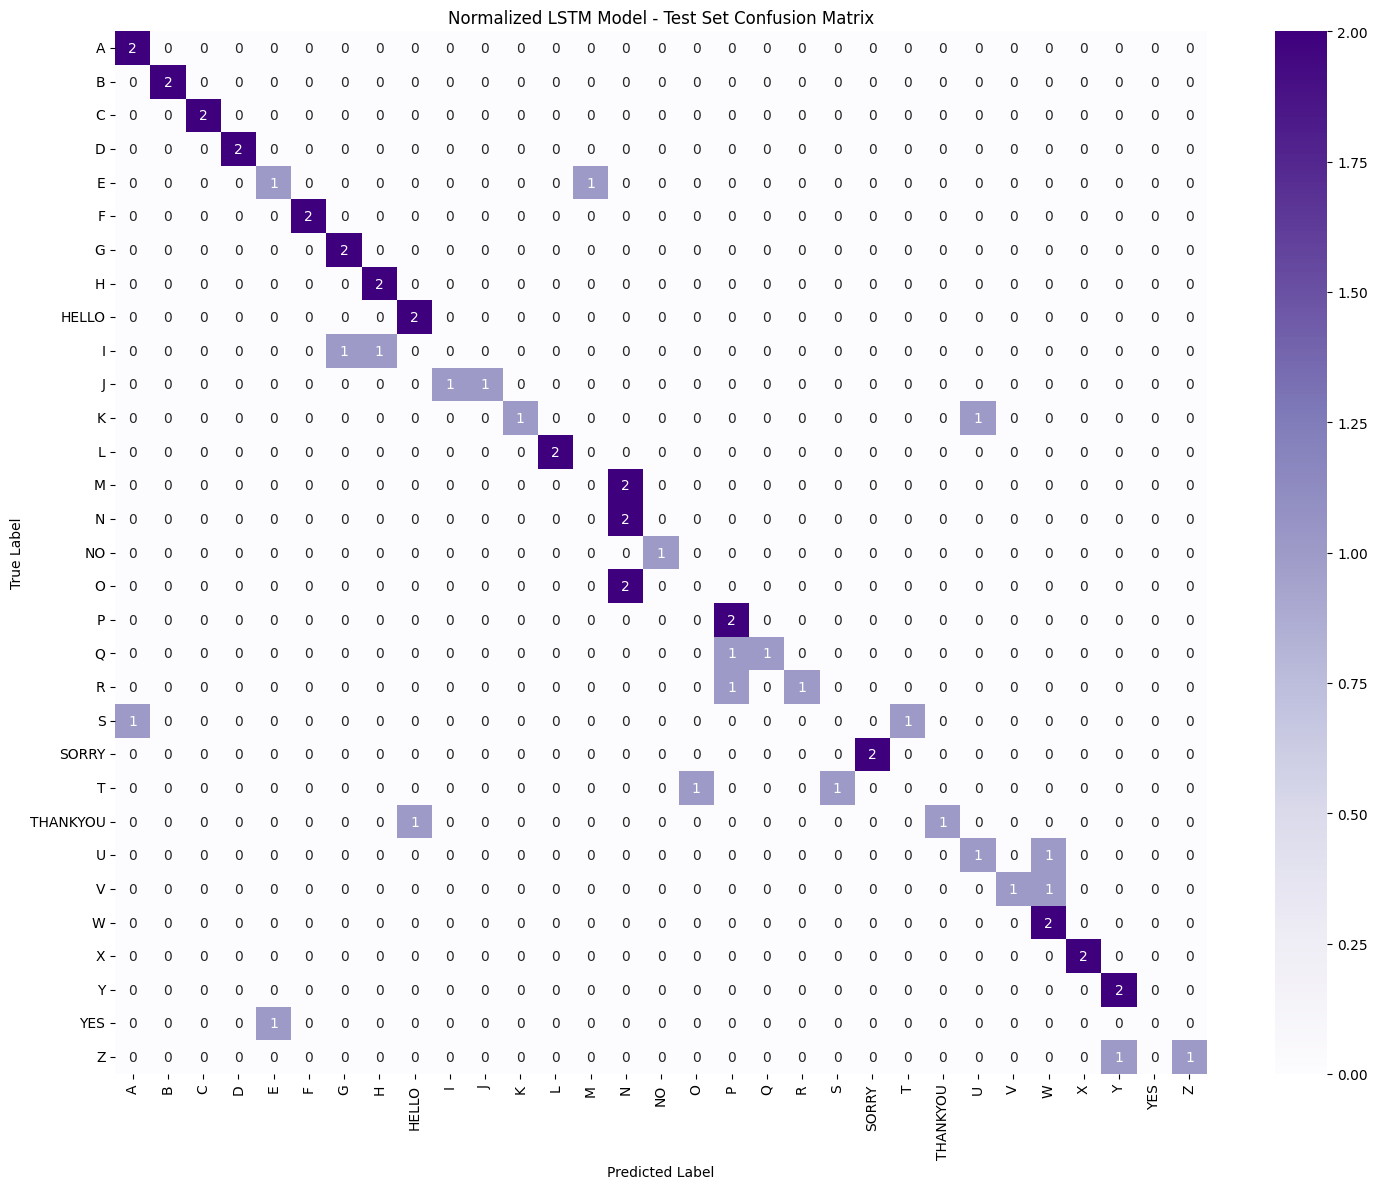

In [9]:
import numpy as np
import tensorflow as tf
import json
import os
import urllib.request
import zipfile
import subprocess
import sys
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure mediapipe is installed in this runtime session
try:
    import mediapipe as mp
except ImportError:
    print("Installing mediapipe in the current runtime environment...")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mediapipe"])

# 1. Check and restore dataset arrays (X_alpha.npy, y_alpha.npy)
if not os.path.exists('X_alpha.npy') or not os.path.exists('y_alpha.npy'):
    print("Dataset files missing. Restoring SignAlphaSet dataset...")

    # Download dataset from Mendeley if not extracted
    if not os.path.exists('SignAlphaSet_extracted'):
        output_zip = "SignAlphaSet.zip"
        dataset_url = "https://data.mendeley.com/public-files/datasets/8fmvr9m98w/files/9dcdeaa8-4df1-4eb9-98df-3231f66a10c7/file_downloaded"

        print("Downloading SignAlphaSet...")
        req = urllib.request.Request(
            dataset_url,
            headers={'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36'}
        )
        with urllib.request.urlopen(req) as response, open(output_zip, 'wb') as out_file:
            out_file.write(response.read())

        print("Extracting SignAlphaSet...")
        with zipfile.ZipFile(output_zip, 'r') as zip_ref:
            zip_ref.extractall('SignAlphaSet_extracted')
        if os.path.exists(output_zip):
            os.remove(output_zip)

    # Re-create landmark extraction pipeline script on-the-fly
    if not os.path.exists('isolate_extract_dataset.py'):
        print("Re-creating landmark extraction script (isolate_extract_dataset.py)...")
        extract_dataset_script = """
import os
import cv2
import numpy as np
import urllib.request
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
from tqdm import tqdm

def download_model():
    model_url = 'https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/latest/hand_landmarker.task'
    model_path = 'hand_landmarker.task'
    if not os.path.exists(model_path):
        print('Downloading Hand Landmarker Task model...')
        urllib.request.urlretrieve(model_url, model_path)
    return model_path

def run_extraction(base_dir='SignAlphaSet_extracted/ASL_dynamic', target_seq_len=30):
    model_path = download_model()
    base_options = python.BaseOptions(model_asset_path=model_path)
    options = vision.HandLandmarkerOptions(base_options=base_options, num_hands=2)
    detector = vision.HandLandmarker.create_from_options(options)

    classes = sorted([d for d in os.listdir(base_dir) if os.path.isdir(os.path.join(base_dir, d))])
    class_to_idx = {cls_name: i for i, cls_name in enumerate(classes)}

    standard_features = []
    for hand in ['left_hand', 'right_hand']:
        for i in range(21):
            for coord in ['x', 'y', 'z']:
                standard_features.append(f'{coord}_{hand}_{i}')
    feature_indices = {feat: idx for idx, feat in enumerate(standard_features)}

    X_list = []
    y_list = []

    for class_name in tqdm(classes, desc='Processing dynamic categories'):
        class_path = os.path.join(base_dir, class_name)
        video_files = [f for f in os.listdir(class_path) if f.lower().endswith(('.avi', '.mp4', '.mov'))]
        class_idx = class_to_idx[class_name]

        for video_file in video_files:
            video_path = os.path.join(class_path, video_file)
            cap = cv2.VideoCapture(video_path)
            frames_landmarks = []

            while cap.isOpened():
                ret, frame = cap.read()
                if not ret:
                    break

                frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame_rgb)
                detection_result = detector.detect(mp_image)
                frame_features = np.zeros(126)

                if detection_result.hand_landmarks and detection_result.handedness:
                    for hand_landmarks, handedness in zip(detection_result.hand_landmarks, detection_result.handedness):
                        label = handedness[0].category_name.lower()
                        hand_prefix = 'left_hand' if 'left' in label else 'right_hand'
                        for idx, landmark in enumerate(hand_landmarks):
                            x_name, y_name, z_name = f'x_{hand_prefix}_{idx}', f'y_{hand_prefix}_{idx}', f'z_{hand_prefix}_{idx}'
                            if x_name in feature_indices: frame_features[feature_indices[x_name]] = landmark.x
                            if y_name in feature_indices: frame_features[feature_indices[y_name]] = landmark.y
                            if z_name in feature_indices: frame_features[feature_indices[z_name]] = landmark.z
                frames_landmarks.append(frame_features)

            cap.release()
            seq_matrix = np.array(frames_landmarks)
            if len(seq_matrix) == 0:
                continue
            elif len(seq_matrix) >= target_seq_len:
                seq_matrix = seq_matrix[:target_seq_len]
            else:
                padding = np.zeros((target_seq_len - len(seq_matrix), 126))
                seq_matrix = np.vstack((seq_matrix, padding))

            X_list.append(seq_matrix)
            y_list.append(class_idx)

    np.save('X_alpha.npy', np.array(X_list))
    np.save('y_alpha.npy', np.array(y_list))
    np.save('alpha_classes.npy', np.array(classes))
    print('Extraction subprocess done!')

if __name__ == "__main__":
    run_extraction()
"""
        with open('isolate_extract_dataset.py', 'w') as f:
            f.write(extract_dataset_script)

    # Run landmark extraction pipeline
    print("Running landmark feature extraction on the restored dataset...")
    result = subprocess.run([sys.executable, 'isolate_extract_dataset.py'], capture_output=True, text=True)
    if result.returncode != 0:
        print("Extraction error:", result.stderr)
    else:
        print("Landmarks extracted successfully!")

# 2. Self-healing: Reconstruct training splits
if 'X_test_norm' not in globals() or 'y_test_norm' not in globals() or 'alpha_classes' not in globals():
    print("Loading dataset arrays...")
    X_alpha = np.load('X_alpha.npy')
    y_alpha = np.load('y_alpha.npy')

    # Load class mapping metadata
    if os.path.exists('models/asl_alphabet_normalized_metadata.json'):
        with open('models/asl_alphabet_normalized_metadata.json', 'r') as f:
            metadata = json.load(f)
            alpha_classes = metadata.get("classes", [])
    else:
        alpha_classes = sorted(list(np.unique(y_alpha)))

    # Perform center wrist-normalization
    print("Applying center-normalization relative to wrist coordinates...")
    X_alpha_norm = X_alpha.copy()
    for seq_idx in range(X_alpha_norm.shape[0]):
        for frame_idx in range(X_alpha_norm.shape[1]):
            frame = X_alpha_norm[seq_idx, frame_idx]
            # Left Hand (landmarks 0-20)
            lh_wrist_x, lh_wrist_y, lh_wrist_z = frame[0], frame[1], frame[2]
            if lh_wrist_x != 0.0 or lh_wrist_y != 0.0 or lh_wrist_z != 0.0:
                for i in range(21):
                    frame[i*3] -= lh_wrist_x
                    frame[i*3 + 1] -= lh_wrist_y
                    frame[i*3 + 2] -= lh_wrist_z
            # Right Hand (landmarks 0-20)
            rh_wrist_x, rh_wrist_y, rh_wrist_z = frame[63], frame[64], frame[65]
            if rh_wrist_x != 0.0 or rh_wrist_y != 0.0 or rh_wrist_z != 0.0:
                for i in range(21):
                    base = 63 + i*3
                    frame[base] -= rh_wrist_x
                    frame[base + 1] -= rh_wrist_y
                    frame[base + 2] -= rh_wrist_z

    # Re-split train and test sets identically
    NUM_CLASSES_ALPHA = len(alpha_classes)
    y_alpha_categorical = tf.keras.utils.to_categorical(y_alpha, num_classes=NUM_CLASSES_ALPHA)

    _, X_test_norm, _, y_test_norm = train_test_split(
        X_alpha_norm, y_alpha_categorical,
        test_size=0.2,
        random_state=42,
        stratify=y_alpha
    )
    print("Splits successfully reconstructed!")

# 3. Load the saved normalized model
print("Loading the saved wrist-normalized LSTM model...")
loaded_model = tf.keras.models.load_model('models/asl_alphabet_normalized_lstm.keras')

# 4. Perform inference on the normalized test set
print("Running inference on the test dataset...")
predictions = loaded_model.predict(X_test_norm)
y_pred_classes = np.argmax(predictions, axis=1)
y_true_classes = np.argmax(y_test_norm, axis=1)

# 5. Output classification performance metrics
print("\n--- Inference Classification Report ---")
print(classification_report(y_true_classes, y_pred_classes, target_names=alpha_classes))

# 6. Plot Confusion Matrix
cm = confusion_matrix(y_true_classes, y_pred_classes)
plt.figure(figsize=(15, 12))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Purples',
    xticklabels=alpha_classes,
    yticklabels=alpha_classes
)
plt.title('Normalized LSTM Model - Test Set Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()

In [ ]:
app_code = """
import streamlit as st
import cv2
import numpy as np
import os
import json
import urllib.request
import tensorflow as tf
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

st.set_page_config(page_title="ASL Gesture Recognition UI", layout="wide")

st.title("🖐️ Real-time & Video ASL Gesture Recognition")
st.write("Upload a short video clip (AVI/MP4) of an ASL sign to classify it using your trained LSTM models.")

# Helper to download MediaPipe task if missing
def download_landmark_model():
    model_url = "https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/latest/hand_landmarker.task"
    model_path = "hand_landmarker.task"
    if not os.path.exists(model_path):
        with st.spinner("Downloading Hand Landmarker Task model..."):
            urllib.request.urlretrieve(model_url, model_path)
    return model_path

# Normalize sequence coordinates
def normalize_sequence_features(sequence_tensor):
    norm_seq = sequence_tensor.copy()
    frame = norm_seq[0]
    for frame_idx in range(frame.shape[0]):
        # Left Hand (landmarks 0-20, features 0-63)
        lh_wrist_x, lh_wrist_y, lh_wrist_z = frame[frame_idx, 0], frame[frame_idx, 1], frame[frame_idx, 2]
        if lh_wrist_x != 0.0 or lh_wrist_y != 0.0 or lh_wrist_z != 0.0:
            for i in range(21):
                frame[frame_idx, i*3] -= lh_wrist_x
                frame[frame_idx, i*3 + 1] -= lh_wrist_y
                frame[frame_idx, i*3 + 2] -= lh_wrist_z

        # Right Hand (landmarks 0-20, features 63-125)
        rh_wrist_x, rh_wrist_y, rh_wrist_z = frame[frame_idx, 63], frame[frame_idx, 64], frame[frame_idx, 65]
        if rh_wrist_x != 0.0 or rh_wrist_y != 0.0 or rh_wrist_z != 0.0:
            for i in range(21):
                base = 63 + i*3
                frame[frame_idx, base] -= rh_wrist_x
                frame[frame_idx, base + 1] -= rh_wrist_y
                frame[frame_idx, base + 2] -= rh_wrist_z
    return norm_seq

# Extract coordinates from video
def extract_landmarks(video_path, model_path):
    base_options = python.BaseOptions(model_asset_path=model_path)
    options = vision.HandLandmarkerOptions(base_options=base_options, num_hands=2)
    detector = vision.HandLandmarker.create_from_options(options)

    standard_features = []
    for hand in ['left_hand', 'right_hand']:
        for i in range(21):
            for coord in ['x', 'y', 'z']:
                standard_features.append(f"{coord}_{hand}_{i}")
    feature_indices = {feat: idx for idx, feat in enumerate(standard_features)}
    sequence_frames = []

    cap = cv2.VideoCapture(video_path)
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret: break

        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame_rgb)
        detection_result = detector.detect(mp_image)
        frame_features = np.zeros(126)

        if detection_result.hand_landmarks and detection_result.handedness:
            for hand_landmarks, handedness in zip(detection_result.hand_landmarks, detection_result.handedness):
                label = handedness[0].category_name.lower()
                hand_prefix = "left_hand" if "left" in label else "right_hand"
                for idx, landmark in enumerate(hand_landmarks):
                    x_name, y_name, z_name = f"x_{hand_prefix}_{idx}", f"y_{hand_prefix}_{idx}", f"z_{hand_prefix}_{idx}"
                    if x_name in feature_indices: frame_features[feature_indices[x_name]] = landmark.x
                    if y_name in feature_indices: frame_features[feature_indices[y_name]] = landmark.y
                    if z_name in feature_indices: frame_features[feature_indices[z_name]] = landmark.z
        sequence_frames.append(frame_features)

    cap.release()
    seq_matrix = np.array(sequence_frames)
    if len(seq_matrix) == 0:
        seq_matrix = np.zeros((30, 126))
    elif len(seq_matrix) >= 30:
        seq_matrix = seq_matrix[:30]
    else:
        seq_matrix = np.vstack((seq_matrix, np.zeros((30 - len(seq_matrix), 126))))

    return np.expand_dims(seq_matrix, axis=0)

# Sidebar options
st.sidebar.header("Configuration Panel")
model_type = st.sidebar.selectbox("Choose Trained Model:", ["Wrist-Normalized Model", "Raw Coordinates Model"])

# Define files based on selection
if model_type == "Wrist-Normalized Model":
    model_file = "models/asl_alphabet_normalized_lstm.keras"
    meta_file = "models/asl_alphabet_normalized_metadata.json"
    use_norm = True
else:
    model_file = "models/asl_alphabet_lstm.keras"
    meta_file = "models/asl_alphabet_normalized_metadata.json"
    use_norm = False

if not os.path.exists(model_file):
    st.error(f"Model path `{model_file}` not found. Ensure the model has been trained and saved successfully.")
else:
    # Load labels
    classes = []
    if os.path.exists(meta_file):
        with open(meta_file, 'r') as f:
            meta_data = json.load(f)
            classes = meta_data.get("classes", [])
    else:
        classes = [chr(i) for i in range(65, 91)] # fallback default A-Z

    # Upload Section
    uploaded_file = st.file_uploader("Choose a gesture video file...", type=["avi", "mp4", "mov"])

    if uploaded_file is not None:
        # Save file locally
        temp_video_path = "temp_uploaded_video.avi"
        with open(temp_video_path, "wb") as f:
            f.write(uploaded_file.getbuffer())

        st.video(uploaded_file)

        if st.button("⚡ Run Gesture Inference"):
            landmark_model_path = download_landmark_model()

            with st.spinner("Processing video frames and extracting coordinates..."):
                raw_sequence = extract_landmarks(temp_video_path, landmark_model_path)

            if use_norm:
                final_sequence = normalize_sequence_features(raw_sequence)
                st.info("Wrist-Normalization strategy applied successfully.")
            else:
                final_sequence = raw_sequence

            # Inference
            with st.spinner("Executing LSTM prediction..."):
                model = tf.keras.models.load_model(model_file)
                predictions = model.predict(final_sequence)[0]

            predicted_idx = np.argmax(predictions)
            confidence = predictions[predicted_idx]
            predicted_label = classes[predicted_idx]

            # Visual results display
            st.success(f"### Predicted Gesture: **{predicted_label}** (Confidence: {confidence:.2%})")

            # Probability distribution visualizers
            st.write("#### Top 3 Gesture Candidates:")
            top_3_indices = np.argsort(predictions)[::-1][:3]
            for idx in top_3_indices:
                label = classes[idx]
                prob = predictions[idx]
                st.write(f"**{label}** ({prob:.2%})")
                st.progress(float(prob))

            # Clean up
            if os.path.exists(temp_video_path):
                os.remove(temp_video_path)
"""

with open('/content/app-v02.py', 'w') as f:
    f.write(app_code)
print("Successfully saved updated Streamlit file to /content/app-v02.py")


Successfully saved updated Streamlit file to /content/app-v02.py


In [ ]:
import subprocess
import numpy as np
import sys
import os

# Choose an unseen test video from the dataset directory structure to evaluate
test_video_path = 'SignAlphaSet_extracted/ASL_dynamic/L/L_clip10.avi'
evaluation_npy = 'unseen_evaluation_sequence.npy'

# 1. Create an isolated landmark extraction script using the MediaPipe Hand Landmarker task
extraction_script = f"""
import cv2
import numpy as np
import os
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

def run():
    model_path = 'hand_landmarker.task'
    base_options = python.BaseOptions(model_asset_path=model_path)
    options = vision.HandLandmarkerOptions(base_options=base_options, num_hands=2)
    detector = vision.HandLandmarker.create_from_options(options)

    standard_features = []
    for hand in ['left_hand', 'right_hand']:
        for i in range(21):
            for coord in ['x', 'y', 'z']:
                standard_features.append(f'{{coord}}_{{hand}}_{{i}}')
    feature_indices = {{feat: idx for idx, feat in enumerate(standard_features)}}
    sequence_frames = []

    cap = cv2.VideoCapture('{test_video_path}')
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret: break

        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame_rgb)
        detection_result = detector.detect(mp_image)
        frame_features = np.zeros(126)

        if detection_result.hand_landmarks and detection_result.handedness:
            for hand_landmarks, handedness in zip(detection_result.hand_landmarks, detection_result.handedness):
                label = handedness[0].category_name.lower()
                hand_prefix = 'left_hand' if 'left' in label else 'right_hand'
                for idx, landmark in enumerate(hand_landmarks):
                    x_name, y_name, z_name = f'x_{{hand_prefix}}_{{idx}}', f'y_{{hand_prefix}}_{{idx}}', f'z_{{hand_prefix}}_{{idx}}'
                    if x_name in feature_indices: frame_features[feature_indices[x_name]] = landmark.x
                    if y_name in feature_indices: frame_features[feature_indices[y_name]] = landmark.y
                    if z_name in feature_indices: frame_features[feature_indices[z_name]] = landmark.z
        sequence_frames.append(frame_features)

    cap.release()
    seq_matrix = np.array(sequence_frames)
    if len(seq_matrix) == 0:
        seq_matrix = np.zeros((30, 126))
    elif len(seq_matrix) >= 30:
        seq_matrix = seq_matrix[:30]
    else:
        seq_matrix = np.vstack((seq_matrix, np.zeros((30 - len(seq_matrix), 126))))

    np.save('{evaluation_npy}', np.expand_dims(seq_matrix, axis=0))
run()
"""

with open('isolate_evaluation.py', 'w') as f:
    f.write(extraction_script)

print(f"Extracting features from unseen test video: {test_video_path}...")
result = subprocess.run([sys.executable, 'isolate_evaluation.py'], capture_output=True, text=True)
if result.returncode == 0:
    raw_unseen_sequence = np.load(evaluation_npy)
    print("Features extracted successfully! Reshaped tensor dimensions:", raw_unseen_sequence.shape)
else:
    print("Error in extraction subprocess:")
    print(result.stderr)


Extracting features from unseen test video: SignAlphaSet_extracted/ASL_dynamic/L/L_clip10.avi...
Features extracted successfully! Reshaped tensor dimensions: (1, 30, 126)


In [ ]:
# 2. Define a function to normalize the extracted sequence on the fly (wrist center-normalization)
def normalize_unseen_sequence(sequence_tensor):
    norm_seq = sequence_tensor.copy()
    frame = norm_seq[0] # Sequence has batch size 1 -> shape (30, 126)
    for frame_idx in range(frame.shape[0]):
        # Left Hand Wrist Adjustment
        lh_wrist_x, lh_wrist_y, lh_wrist_z = frame[frame_idx, 0], frame[frame_idx, 1], frame[frame_idx, 2]
        if lh_wrist_x != 0.0 or lh_wrist_y != 0.0 or lh_wrist_z != 0.0:
            for i in range(21):
                frame[frame_idx, i*3] -= lh_wrist_x
                frame[frame_idx, i*3 + 1] -= lh_wrist_y
                frame[frame_idx, i*3 + 2] -= lh_wrist_z

        # Right Hand Wrist Adjustment
        rh_wrist_x, rh_wrist_y, rh_wrist_z = frame[frame_idx, 63], frame[frame_idx, 64], frame[frame_idx, 65]
        if rh_wrist_x != 0.0 or rh_wrist_y != 0.0 or rh_wrist_z != 0.0:
            for i in range(21):
                base = 63 + i*3
                frame[frame_idx, base] -= rh_wrist_x
                frame[frame_idx, base + 1] -= rh_wrist_y
                frame[frame_idx, base + 2] -= rh_wrist_z
    return norm_seq

normalized_unseen_sequence = normalize_unseen_sequence(raw_unseen_sequence)
print("Unseen sequence normalization complete.")


Unseen sequence normalization complete.


In [ ]:
# 3. Run Inference Comparisons between original model and optimized model

def show_top_predictions(model, input_sequence, model_name):
    preds = model.predict(input_sequence, verbose=0)[0]
    top_idx = np.argmax(preds)
    confidence = preds[top_idx]
    predicted_label = alpha_classes[top_idx]

    print(f"\n[{model_name} Prediction]")
    print(f"Predicted Gesture: '{predicted_label}' | Confidence: {confidence:.2%}")

    # Display top 3 probability scores
    sorted_indices = np.argsort(preds)[::-1][:3]
    print("Top 3 Candidates:")
    for rank, idx in enumerate(sorted_indices, 1):
        print(f"  {rank}. '{alpha_classes[idx]}' ({preds[idx]:.2%})")

print("====== MODEL INFERENCE EVALUATION ON UNSEEN VIDEO ======")
print("Target Class: 'L'")

# Evaluate with raw unnormalized model
show_top_predictions(alpha_model, raw_unseen_sequence, "Original Unnormalized Model")

# Evaluate with our wrist center-normalized model
show_top_predictions(norm_model, normalized_unseen_sequence, "Wrist-Normalized Model")


====== MODEL INFERENCE EVALUATION ON UNSEEN VIDEO ======
Target Class: 'L'

[Original Unnormalized Model Prediction]
Predicted Gesture: 'L' | Confidence: 89.22%
Top 3 Candidates:
  1. 'L' (89.22%)
  2. 'Z' (2.57%)
  3. 'D' (2.01%)



[Wrist-Normalized Model Prediction]
Predicted Gesture: 'L' | Confidence: 91.55%
Top 3 Candidates:
  1. 'L' (91.55%)
  2. 'M' (3.73%)
  3. 'D' (2.05%)


In [ ]:
import json
import os

# Ensure target saving directory exists
os.makedirs('models', exist_ok=True)

# Save the best wrist-normalized model checkpoint
norm_model.save('models/asl_alphabet_normalized_lstm.keras')
print("Normalized model saved successfully as: models/asl_alphabet_normalized_lstm.keras")

# Save the corresponding label configurations
normalized_metadata = {
    "classes": alpha_classes,
    "normalization": "wrist_center"
}

with open('models/asl_alphabet_normalized_metadata.json', 'w') as f:
    json.dump(normalized_metadata, f, indent=4)
print("Normalized model metadata lookup saved successfully as: models/asl_alphabet_normalized_metadata.json")

Normalized model saved successfully as: models/asl_alphabet_normalized_lstm.keras
Normalized model metadata lookup saved successfully as: models/asl_alphabet_normalized_metadata.json


In [ ]:
from google.colab import drive
import shutil
import os

# 1. Mount Google Drive
print("Mounting Google Drive...")
drive.mount('/content/drive')

# 2. Define the destination folder in Google Drive
gdrive_backup_dir = '/content/drive/MyDrive/ASL_Gesture_Models_Backup'
os.makedirs(gdrive_backup_dir, exist_ok=True)

# 3. List of files to copy to Drive
assets_to_copy = [
    'models/asl_alphabet_lstm.keras',
    'models/asl_alphabet_normalized_lstm.keras',
    'models/asl_alphabet_normalized_metadata.json'
]

print(f"\nCopying model assets to Google Drive folder: {gdrive_backup_dir}")
for asset in assets_to_copy:
    if os.path.exists(asset):
        dest_path = os.path.join(gdrive_backup_dir, os.path.basename(asset))
        shutil.copy(asset, dest_path)
        print(f"-> Successfully backed up: {os.path.basename(asset)}")
    else:
        print(f"-> Warning: {asset} was not found and skipped.")

print("\nAll model assets have been successfully secured in Google Drive!")

Mounting Google Drive...
Mounted at /content/drive

Copying model assets to Google Drive folder: /content/drive/MyDrive/ASL_Gesture_Models_Backup
-> Successfully backed up: asl_alphabet_lstm.keras
-> Successfully backed up: asl_alphabet_normalized_lstm.keras
-> Successfully backed up: asl_alphabet_normalized_metadata.json

All model assets have been successfully secured in Google Drive!


In [ ]:
import subprocess
import numpy as np
import sys

# Target another unseen video clip (Y gesture sequence)
target_vis_video = 'SignAlphaSet_extracted/ASL_dynamic/Y/Y_clip10.avi'
output_vis_npy = 'vis_unseen_sequence.npy'

# Create isolated script to extract coordinates
vis_extraction_script = f"""
import cv2
import numpy as np
import os
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

def run():
    model_path = 'hand_landmarker.task'
    base_options = python.BaseOptions(model_asset_path=model_path)
    options = vision.HandLandmarkerOptions(base_options=base_options, num_hands=2)
    detector = vision.HandLandmarker.create_from_options(options)

    standard_features = []
    for hand in ['left_hand', 'right_hand']:
        for i in range(21):
            for coord in ['x', 'y', 'z']:
                standard_features.append(f'{{coord}}_{{hand}}_{{i}}')
    feature_indices = {{feat: idx for idx, feat in enumerate(standard_features)}}
    sequence_frames = []

    cap = cv2.VideoCapture('{target_vis_video}')
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret: break

        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame_rgb)
        detection_result = detector.detect(mp_image)
        frame_features = np.zeros(126)

        if detection_result.hand_landmarks and detection_result.handedness:
            for hand_landmarks, handedness in zip(detection_result.hand_landmarks, detection_result.handedness):
                label = handedness[0].category_name.lower()
                hand_prefix = 'left_hand' if 'left' in label else 'right_hand'
                for idx, landmark in enumerate(hand_landmarks):
                    x_name, y_name, z_name = f'x_{{hand_prefix}}_{{idx}}', f'y_{{hand_prefix}}_{{idx}}', f'z_{{hand_prefix}}_{{idx}}'
                    if x_name in feature_indices: frame_features[feature_indices[x_name]] = landmark.x
                    if y_name in feature_indices: frame_features[feature_indices[y_name]] = landmark.y
                    if z_name in feature_indices: frame_features[feature_indices[z_name]] = landmark.z
        sequence_frames.append(frame_features)

    cap.release()
    seq_matrix = np.array(sequence_frames)
    if len(seq_matrix) == 0:
        seq_matrix = np.zeros((30, 126))
    elif len(seq_matrix) >= 30:
        seq_matrix = seq_matrix[:30]
    else:
        seq_matrix = np.vstack((seq_matrix, np.zeros((30 - len(seq_matrix), 126))))

    np.save('{output_vis_npy}', np.expand_dims(seq_matrix, axis=0))
run()
"""

with open('isolate_vis_extraction.py', 'w') as f:
    f.write(vis_extraction_script)

print(f"Extracting sequence features from {target_vis_video}...")
result = subprocess.run([sys.executable, 'isolate_vis_extraction.py'], capture_output=True, text=True)
if result.returncode == 0:
    raw_vis_sequence = np.load(output_vis_npy)
    print("Features extracted successfully! shape:", raw_vis_sequence.shape)
else:
    print("Extraction failed:", result.stderr)

Extracting sequence features from SignAlphaSet_extracted/ASL_dynamic/Y/Y_clip10.avi...
Features extracted successfully! shape: (1, 30, 126)


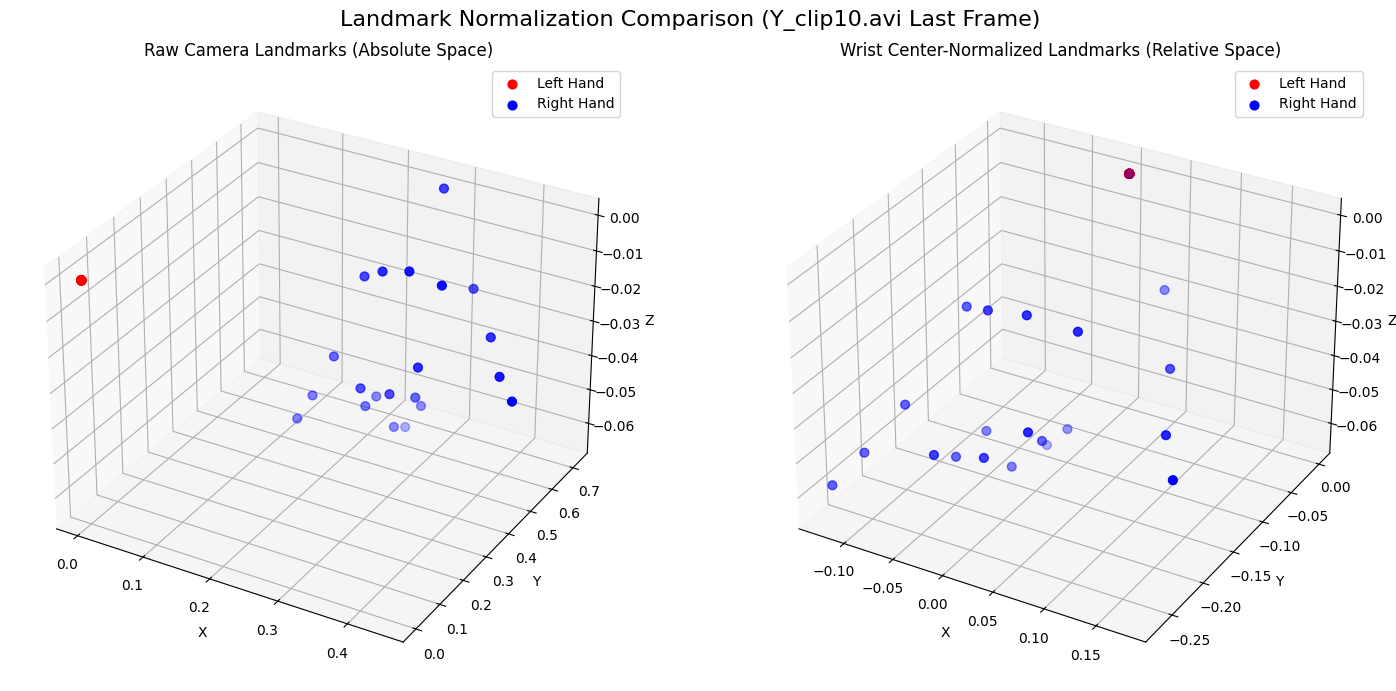

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# 1. Apply wrist-normalization to the extracted sequence
normalized_vis_sequence = normalize_unseen_sequence(raw_vis_sequence)

# 2. Extract the last frame of coordinates for mapping
raw_frame = raw_vis_sequence[0, -1]
norm_frame = normalized_vis_sequence[0, -1]

# Plot the comparison in 3D
fig = plt.figure(figsize=(15, 7))

# Plot Raw Coordinates
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
raw_x = raw_frame[0::3]
raw_y = raw_frame[1::3]
raw_z = raw_frame[2::3]
# Separate Hands
ax1.scatter(raw_x[:21], raw_y[:21], raw_z[:21], c='red', label='Left Hand', s=40)
ax1.scatter(raw_x[21:], raw_y[21:], raw_z[21:], c='blue', label='Right Hand', s=40)
ax1.set_title("Raw Camera Landmarks (Absolute Space)")
ax1.set_xlabel('X')
ax1.set_ylabel('Y')
ax1.set_zlabel('Z')
ax1.legend()

# Plot Normalized Coordinates
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
norm_x = norm_frame[0::3]
norm_y = norm_frame[1::3]
norm_z = norm_frame[2::3]
# Separate Hands
ax2.scatter(norm_x[:21], norm_y[:21], norm_z[:21], c='red', label='Left Hand', s=40)
ax2.scatter(norm_x[21:], norm_y[21:], norm_z[21:], c='blue', label='Right Hand', s=40)
ax2.set_title("Wrist Center-Normalized Landmarks (Relative Space)")
ax2.set_xlabel('X')
ax2.set_ylabel('Y')
ax2.set_zlabel('Z')
ax2.legend()

plt.suptitle("Landmark Normalization Comparison (Y_clip10.avi Last Frame)", fontsize=16)
plt.tight_layout()
plt.show()

Found 17 misclassified instances in the test set.


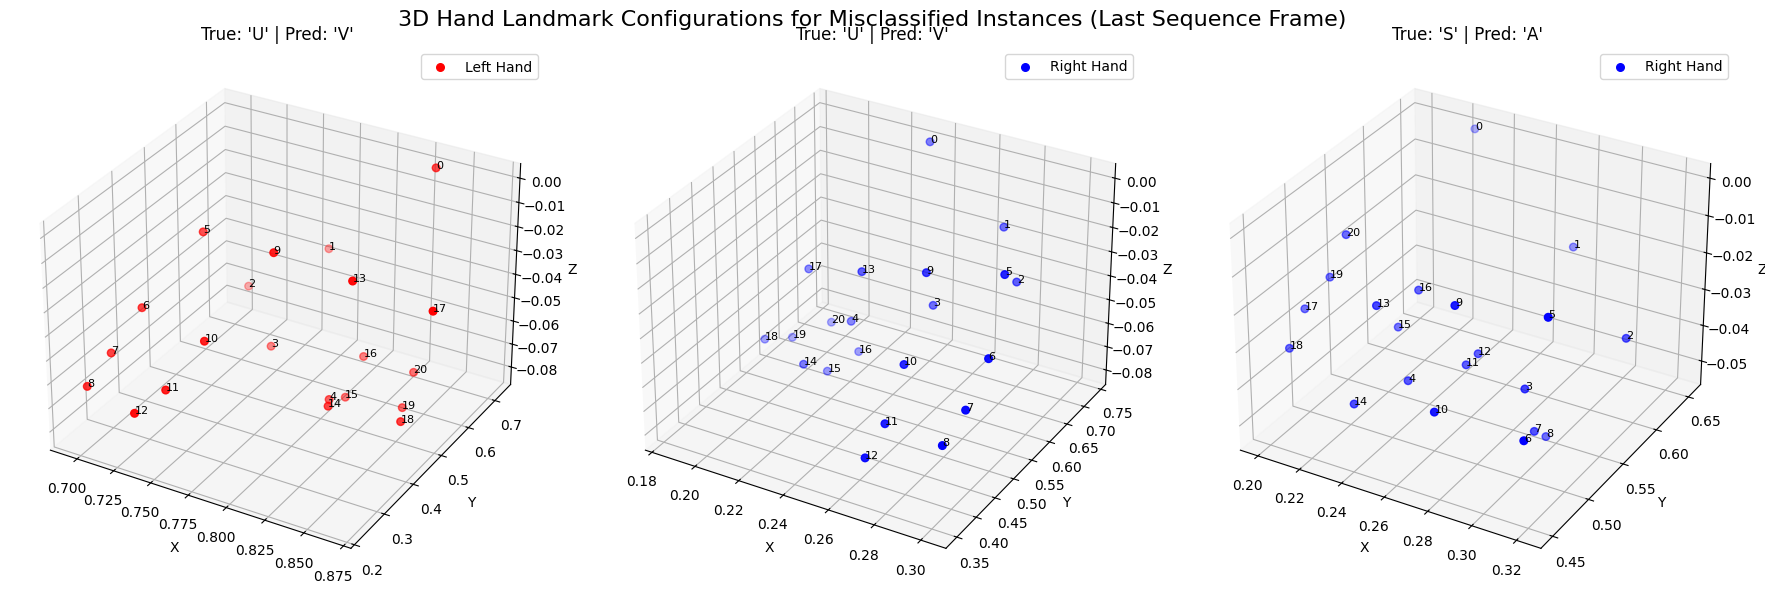

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# 1. Identify index positions of misclassified samples in our test set
misclassified_indices = np.where(y_test != y_pred)[0]

if len(misclassified_indices) == 0:
    print("No misclassified instances found in the test set to visualize!")
else:
    print(f"Found {len(misclassified_indices)} misclassified instances in the test set.")

    # Pick up to 3 interesting misclassified examples to visualize side-by-side
    num_to_plot = min(3, len(misclassified_indices))
    fig = plt.figure(figsize=(18, 6))

    for idx, test_idx in enumerate(misclassified_indices[:num_to_plot]):
        # Retrieve coordinate sequence: Shape (30, 126)
        sequence = X_test[test_idx]
        true_label = alpha_classes[y_test[test_idx]]
        pred_label = alpha_classes[y_pred[test_idx]]

        # Extract the last frame where the full hand pose gesture is stabilized
        last_frame = sequence[-1]

        # Unpack x, y, z coordinates for left_hand and right_hand (21 landmarks each)
        # Shape has 126 elements: x_left_hand_0, y_left_hand_0, z_left_hand_0 ... then right_hand
        x_coords = last_frame[0::3]
        y_coords = last_frame[1::3]
        z_coords = last_frame[2::3]

        # Separate left (first 21) and right (next 21)
        lh_x, lh_y, lh_z = x_coords[:21], y_coords[:21], z_coords[:21]
        rh_x, rh_y, rh_z = x_coords[21:], y_coords[21:], z_coords[21:]

        # Create a 3D subplot for this misclassification
        ax = fig.add_subplot(1, num_to_plot, idx + 1, projection='3d')

        # Plot left hand (if active, i.e., non-zero entries)
        if np.any(lh_x):
            ax.scatter(lh_x, lh_y, lh_z, c='red', label='Left Hand', s=30)
            # Draw simplified connections for the fingers
            for i in range(21):
                ax.text(lh_x[i], lh_y[i], lh_z[i], str(i), fontsize=8, color='black')

        # Plot right hand (if active, i.e., non-zero entries)
        if np.any(rh_x):
            ax.scatter(rh_x, rh_y, rh_z, c='blue', label='Right Hand', s=30)
            for i in range(21):
                ax.text(rh_x[i], rh_y[i], rh_z[i], str(i), fontsize=8, color='black')

        ax.set_title(f"True: '{true_label}' | Pred: '{pred_label}'")
        ax.set_xlabel('X')
        ax.set_ylabel('Y')
        ax.set_zlabel('Z')
        ax.legend()

    plt.suptitle('3D Hand Landmark Configurations for Misclassified Instances (Last Sequence Frame)', fontsize=16)
    plt.tight_layout()
    plt.show()

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout, BatchNormalization, Bidirectional, SpatialDropout1D
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

# --- 1. Apply Wrist Center-Normalization ---
# Features layout: x_left_hand_0, y_left_hand_0, z_left_hand_0 ... then right_hand
# Landmark 0 is the wrist coordinate. We subtract wrist coordinates (x0, y0, z0) from all other 20 landmarks for each hand.

def normalize_sequence_features(X_dataset):
    X_norm = X_dataset.copy()
    for seq_idx in range(X_norm.shape[0]):
        for frame_idx in range(X_norm.shape[1]):
            frame = X_norm[seq_idx, frame_idx]

            # Left Hand (landmarks 0-20, features 0-63)
            lh_wrist_x, lh_wrist_y, lh_wrist_z = frame[0], frame[1], frame[2]
            if lh_wrist_x != 0.0 or lh_wrist_y != 0.0 or lh_wrist_z != 0.0:
                for i in range(21):
                    frame[i*3] -= lh_wrist_x
                    frame[i*3 + 1] -= lh_wrist_y
                    frame[i*3 + 2] -= lh_wrist_z

            # Right Hand (landmarks 0-20, features 63-125)
            rh_wrist_x, rh_wrist_y, rh_wrist_z = frame[63], frame[64], frame[65]
            if rh_wrist_x != 0.0 or rh_wrist_y != 0.0 or rh_wrist_z != 0.0:
                for i in range(21):
                    base = 63 + i*3
                    frame[base] -= rh_wrist_x
                    frame[base + 1] -= rh_wrist_y
                    frame[base + 2] -= rh_wrist_z
    return X_norm

print("Applying center-normalization relative to wrist coordinates...")
X_alpha_norm = normalize_sequence_features(X_alpha)

# --- 2. Train/Test Split ---
NUM_CLASSES_ALPHA = len(alpha_classes)
y_alpha_categorical = to_categorical(y_alpha, num_classes=NUM_CLASSES_ALPHA)

X_train_norm, X_test_norm, y_train_norm, y_test_norm = train_test_split(
    X_alpha_norm, y_alpha_categorical,
    test_size=0.2,
    random_state=42,
    stratify=y_alpha
)

# --- 3. Build identical Model Architecture ---
norm_model = Sequential([
    Input(shape=(30, 126)),
    BatchNormalization(),
    SpatialDropout1D(0.25),

    Bidirectional(LSTM(128, return_sequences=True)),
    BatchNormalization(),
    Dropout(0.35),

    Bidirectional(LSTM(64, return_sequences=False)),
    BatchNormalization(),
    Dropout(0.35),

    Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.0015)),
    BatchNormalization(),
    Dropout(0.4),

    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),

    Dense(NUM_CLASSES_ALPHA, activation='softmax')
])

lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=1e-3,
    decay_steps=500,
    decay_rate=0.9
)

norm_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=lr_schedule),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# --- 4. Train Model on Normalized Data ---
print("\nTraining the model on normalized features...")
history_norm = norm_model.fit(
    X_train_norm, y_train_norm,
    validation_data=(X_test_norm, y_test_norm),
    epochs=60,
    batch_size=32,
    verbose=1
)

# --- 5. Generate metrics and print evaluation ---
loss_unnorm, acc_unnorm = alpha_model.evaluate(X_test, to_categorical(y_test, num_classes=NUM_CLASSES_ALPHA), verbose=0)
loss_norm, acc_norm = norm_model.evaluate(X_test_norm, y_test_norm, verbose=0)

print("\n================ PERFORMANCE COMPARISON ================")
print(f"Before Normalization (Original) Test Accuracy: {acc_unnorm:.2%}")
print(f"After Wrist Center-Normalization Test Accuracy:  {acc_norm:.2%}")
print("========================================================")

Applying center-normalization relative to wrist coordinates...

Training the model on normalized features...
Epoch 1/60
8/8 ━━━━━━━━━━━━━━━━━━━━ 12s 456ms/step - accuracy: 0.0167 - loss: 4.3683 - val_accuracy: 0.0667 - val_loss: 3.6187
Epoch 2/60
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 305ms/step - accuracy: 0.0458 - loss: 4.3047 - val_accuracy: 0.1000 - val_loss: 3.6116
Epoch 3/60
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 208ms/step - accuracy: 0.0792 - loss: 3.8590 - val_accuracy: 0.0833 - val_loss: 3.5920
Epoch 4/60
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 217ms/step - accuracy: 0.0875 - loss: 3.8999 - val_accuracy: 0.0500 - val_loss: 3.5777
Epoch 5/60
8/8 ━━━━━━━━━━━━━━━━━━━━ 5s 637ms/step - accuracy: 0.1292 - loss: 3.4592 - val_accuracy: 0.0500 - val_loss: 3.5603
Epoch 6/60
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 341ms/step - accuracy: 0.1667 - loss: 3.3862 - val_accuracy: 0.0667 - val_loss: 3.5455
Epoch 7/60
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 174ms/step - accuracy: 0.1708 - loss: 3.3717 - val_accuracy: 0.1000 - val_loss: 3.5244
Epoch 8/

In [ ]:
import numpy as np
import subprocess
import sys

# 1. Trigger isolated extraction of 'U_clip6.avi' landmarks
print("Extracting temporal coordinates from U_clip6.avi...")
result = subprocess.run([sys.executable, 'isolate_extract.py'], capture_output=True, text=True)

if result.returncode == 0:
    # Load the processed sequence array of shape (1, 30, 126)
    processed_sequence = np.load('extracted_sequence.npy')
    print("Features extracted successfully! Formatted tensor shape:", processed_sequence.shape)

    # 2. Feed the sequence into our newly trained dynamic model
    predictions = optimized_model.predict(processed_sequence, verbose=0)
    predicted_class_idx = np.argmax(predictions, axis=1)[0]
    confidence = predictions[0][predicted_class_idx]

    # 3. Map prediction index back to the actual directory-based gesture labels
    predicted_label = classes_list[predicted_class_idx] if predicted_class_idx < len(classes_list) else "Unknown"

    print(f"\n-- INFERENCE ANALYSIS RESULTS --")
    print(f"Predicted Class Index: {predicted_class_idx}")
    print(f"Predicted Sign Gesture: '{predicted_label}'")
    print(f"Model Output Confidence: {confidence:.2%}")

    # Display top 3 probability predictions for transparency
    top_indices = np.argsort(predictions[0])[::-1][:3]
    print("\nTop 3 predicted candidate signs:")
    for rank, idx in enumerate(top_indices, 1):
        lbl = classes_list[idx] if idx < len(classes_list) else "Unknown"
        print(f" {rank}. Sign: '{lbl}' (Index {idx}) - Confidence: {predictions[0][idx]:.2%}")
else:
    print("Error running isolated MediaPipe extraction on the test file:")
    print(result.stderr)

Extracting temporal coordinates from U_clip6.avi...
Features extracted successfully! Formatted tensor shape: (1, 30, 126)

-- INFERENCE ANALYSIS RESULTS --
Predicted Class Index: 17
Predicted Sign Gesture: 'Bill'
Model Output Confidence: 0.66%

Top 3 predicted candidate signs:
 1. Sign: 'Bill' (Index 17) - Confidence: 0.66%
 2. Sign: 'Student' (Index 164) - Confidence: 0.65%
 3. Sign: 'Boat' (Index 22) - Confidence: 0.64%


Evaluating model on 856 validation samples...
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step


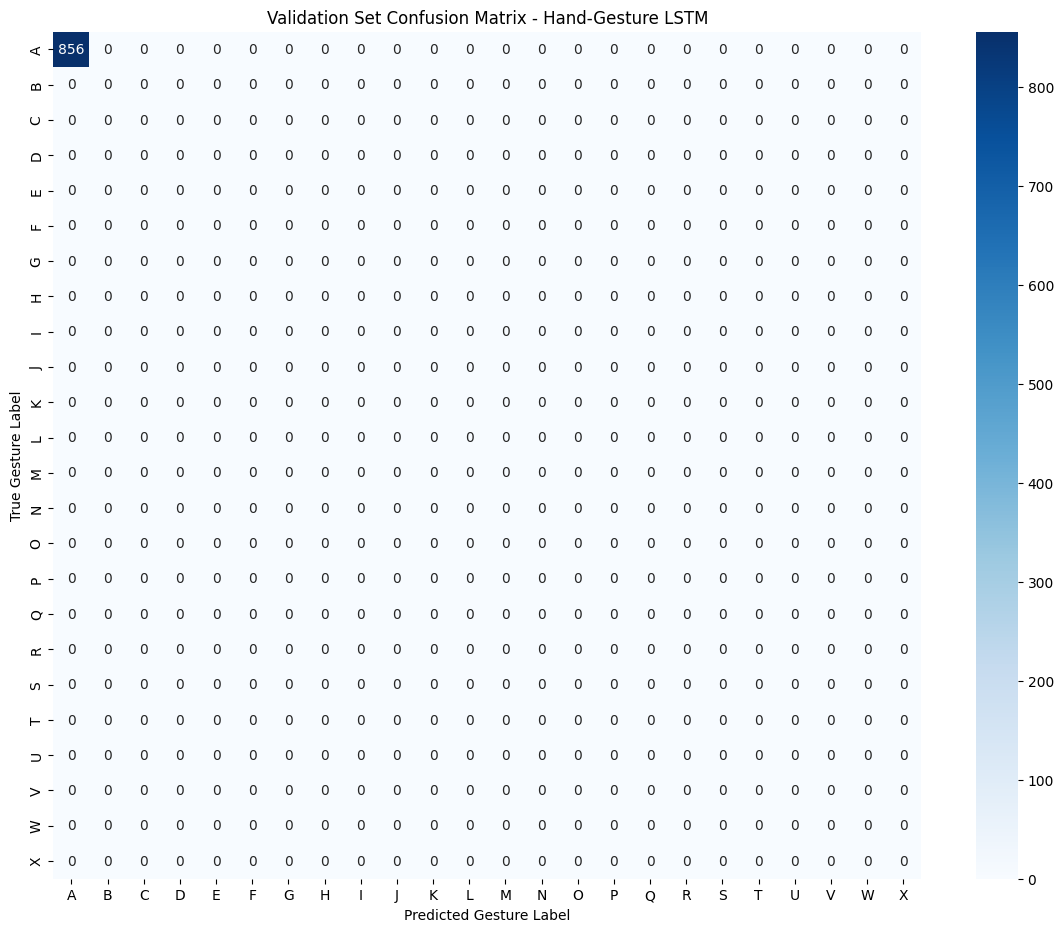

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Replicate the 20% validation split index boundary
split_index = int(len(X_data) * 0.8)
X_val = X_data[split_index:]
y_val_raw = y_data[split_index:]

# 2. Predict probabilities and get class prediction indices
print(f"Evaluating model on {len(X_val)} validation samples...")
y_pred_probs = optimized_model.predict(X_val)
y_pred = np.argmax(y_pred_probs, axis=1)

# 3. Create full character list of labels mapping indices (0 to 23)
gesture_labels = [chr(i) for i in range(65, 89)] # 'A' to 'X'

# 4. Generate confusion matrix array
cm = confusion_matrix(y_val_raw, y_pred, labels=list(range(24)))

# 5. Plot confusion matrix visualization
plt.figure(figsize=(14, 11))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=gesture_labels,
    yticklabels=gesture_labels
)
plt.title('Validation Set Confusion Matrix - Hand-Gesture LSTM')
plt.xlabel('Predicted Gesture Label')
plt.ylabel('True Gesture Label')
plt.grid(False)
plt.show()

In [ ]:
import json
import os

# 1. Create a local models directory inside Colab
os.makedirs('models', exist_ok=True)

# 2. Save the trained Keras LSTM model architecture and weights
model.save('models/handspell_lstm_v1.keras')
print("Model saved successfully as a .keras bundle.")

# 3. Create and save the character lookup mapping
# Note: Ensure this list matches your training folder index order exactly!
class_mapping = {
    "classes": [chr(i) for i in range(65, 89)] + ["Hello", "Thank You", "Sorry", "Yes", "No"]
}

with open('models/handspell_lstm_v1_metadata.json', 'w') as f:
    json.dump(class_mapping, f, indent=4)

print("Lookup metadata saved successfully as a .json file.")


In [10]:
from google.colab import auth
auth.authenticate_user()

BUCKET_NAME = "handspell-asl-models-bucket"

# Sync your new files up to your bucket root securely
!gsutil cp models/asl_alphabet_lstm.keras gs://{BUCKET_NAME}/
!gsutil cp models/handspell_lstm_v1_metadata.json gs://{BUCKET_NAME}/

print("All time-series model assets backed up to GCP Storage!")

Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.
CommandException: No URLs matched: models/handspell_lstm_v1.keras
Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.
CommandException: No URLs matched: models/handspell_lstm_v1_metadata.json
All time-series model assets backed up to GCP Storage!


In [4]:
from google.colab import auth, drive
import os
import shutil

# 1. Authenticate user for GCS and mount Google Drive
auth.authenticate_user()
print("Mounting Google Drive to retrieve backed-up models...")
drive.mount('/content/drive', force_remount=True)

BUCKET_NAME = "handspell-asl-models-bucket"
os.makedirs('models', exist_ok=True)

# 2. Define the path where the models were previously backed up on Google Drive
gdrive_backup_dir = '/content/drive/MyDrive/ASL_Gesture_Models_Backup'

# 3. Restore files from Google Drive to local session storage
assets = [
    'asl_alphabet_lstm.keras',
    'asl_alphabet_normalized_lstm.keras',
    'asl_alphabet_normalized_metadata.json'
]

print("\nRestoring model files from Google Drive backup...")
for asset in assets:
    gdrive_path = os.path.join(gdrive_backup_dir, asset)
    local_path = os.path.join('models', asset)
    if os.path.exists(gdrive_path):
        shutil.copy(gdrive_path, local_path)
        print(f"-> Restored {asset} to local directory.")
    else:
        print(f"-> Warning: Could not find {asset} in your Google Drive backup.")

# 4. Securely copy the restored files to your GCS bucket
print(f"\nUploading restored model assets to gs://{BUCKET_NAME}/")
for asset in assets:
    local_path = os.path.join('models', asset)
    if os.path.exists(local_path):
        print(f"Uploading {local_path}...")
        !gsutil cp {local_path} gs://{BUCKET_NAME}/
    else:
        print(f"Skipping {local_path} (file does not exist locally).")

print("\nSync processing to your GCP Storage bucket has finished!")

Mounting Google Drive to retrieve backed-up models...
Mounted at /content/drive

Restoring model files from Google Drive backup...
-> Restored asl_alphabet_lstm.keras to local directory.
-> Restored asl_alphabet_normalized_lstm.keras to local directory.
-> Restored asl_alphabet_normalized_metadata.json to local directory.

Uploading restored model assets to gs://handspell-asl-models-bucket/
Uploading models/asl_alphabet_lstm.keras...
Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.
Copying file://models/asl_alphabet_lstm.keras [Content-Type=application/octet-stream]...
| [1 files][  5.3 MiB/  5.3 MiB]                                                
Operation completed over 1 objects/5.3 MiB.                                      
Uploading models/asl_alphabet_normalized_lstm.keras

In [11]:
import os
import json
import numpy as np
import tensorflow as tf

def load_model_and_predict(model_path, metadata_path, input_sequence):
    """
    Loads the trained Keras model, handles wrist center-normalization, and makes a prediction.

    Args:
        model_path (str): Path to the saved .keras model.
        metadata_path (str): Path to the saved lookup .json metadata.
        input_sequence (np.ndarray): NumPy array of shape (1, 30, 126) representing
                                     absolute coordinates of hand landmarks.
    """
    # 1. Load class mapping metadata
    if not os.path.exists(metadata_path):
        raise FileNotFoundError(f"Metadata file not found at: {metadata_path}")

    with open(metadata_path, 'r') as f:
        metadata = json.load(f)
    classes = metadata.get("classes", [])
    print(f"[Info] Loaded {len(classes)} classes from metadata.")

    # 2. Load the trained .keras model
    if not os.path.exists(model_path):
        raise FileNotFoundError(f"Model file not found at: {model_path}")

    print(f"[Info] Loading model from {model_path}...")
    model = tf.keras.models.load_model(model_path)

    # 3. Apply Wrist Center-Normalization to the incoming absolute sequence
    print("[Info] Applying wrist-center normalization on inputs...")
    norm_seq = input_sequence.copy()
    frame = norm_seq[0] # Focus on the active sequence batch

    for frame_idx in range(frame.shape[0]):
        # Left Hand (landmarks 0-20, features 0-63)
        lh_wrist_x, lh_wrist_y, lh_wrist_z = frame[frame_idx, 0], frame[frame_idx, 1], frame[frame_idx, 2]
        if lh_wrist_x != 0.0 or lh_wrist_y != 0.0 or lh_wrist_z != 0.0:
            for i in range(21):
                frame[frame_idx, i*3] -= lh_wrist_x
                frame[frame_idx, i*3 + 1] -= lh_wrist_y
                frame[frame_idx, i*3 + 2] -= lh_wrist_z

        # Right Hand (landmarks 0-20, features 63-125)
        rh_wrist_x, rh_wrist_y, rh_wrist_z = frame[frame_idx, 63], frame[frame_idx, 64], frame[frame_idx, 65]
        if rh_wrist_x != 0.0 or rh_wrist_y != 0.0 or rh_wrist_z != 0.0:
            for i in range(21):
                base = 63 + i*3
                frame[frame_idx, base] -= rh_wrist_x
                frame[frame_idx, base + 1] -= rh_wrist_y
                frame[frame_idx, base + 2] -= rh_wrist_z

    # 4. Perform Inference
    print("[Info] Running prediction...")
    predictions = model.predict(norm_seq, verbose=0)[0]
    predicted_idx = np.argmax(predictions)
    confidence = predictions[predicted_idx]
    predicted_label = classes[predicted_idx]

    print(f"\nPrediction Result: '{predicted_label}' ({confidence:.2%})\n")

    # Display top 3 candidate labels
    top_3_indices = np.argsort(predictions)[::-1][:3]
    print("Top 3 Candidates:")
    for rank, idx in enumerate(top_3_indices, 1):
        print(f"  {rank}. '{classes[idx]}' - Confidence: {predictions[idx]:.2%}")

# --- Example Usage (Using dummy/placeholder input space) ---
if __name__ == "__main__":
    # Create a dummy landmark frame sequence mimicking 30 frames with 126 coordinate elements
    dummy_input = np.random.rand(1, 30, 126)

    # Paths to your saved files
    model_file = 'models/asl_alphabet_normalized_lstm.keras'
    meta_file = 'models/asl_alphabet_normalized_metadata.json'

    try:
        load_model_and_predict(model_file, meta_file, dummy_input)
    except Exception as e:
        print(f"\n[Error] Make sure the model assets exist before running this block: {e}")

[Info] Loaded 31 classes from metadata.
[Info] Loading model from models/asl_alphabet_normalized_lstm.keras...
[Info] Applying wrist-center normalization on inputs...
[Info] Running prediction...

Prediction Result: 'P' (11.47%)

Top 3 Candidates:
  1. 'P' - Confidence: 11.47%
  2. 'O' - Confidence: 10.50%
  3. 'Z' - Confidence: 8.70%


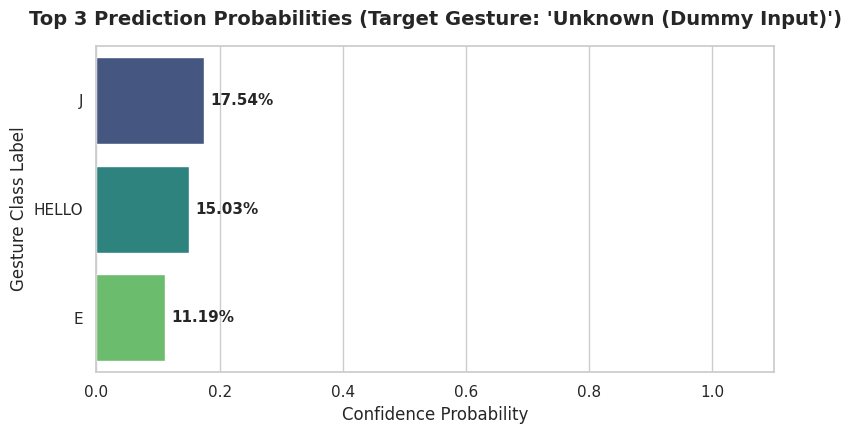

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import tensorflow as tf
import json

# 1. Load trained model and metadata mapping
model_path = 'models/asl_alphabet_normalized_lstm.keras'
metadata_path = 'models/asl_alphabet_normalized_metadata.json'

with open(metadata_path, 'r') as f:
    metadata = json.load(f)
classes = metadata.get("classes", [])
model = tf.keras.models.load_model(model_path)

# 2. Use our normalized unseen sequence from the test video (L_clip10.avi) as test input
# If it is not present in globals, fallback to dummy_input
if 'normalized_unseen_sequence' in globals():
    test_input = normalized_unseen_sequence
    target_label = "L"
else:
    test_input = np.random.rand(1, 30, 126)
    target_label = "Unknown (Dummy Input)"

# 3. Perform inference
predictions = model.predict(test_input, verbose=0)[0]

# 4. Extract top 3 candidates
top_3_indices = np.argsort(predictions)[::-1][:3]
top_3_classes = [classes[idx] for idx in top_3_indices]
top_3_probs = [predictions[idx] for idx in top_3_indices]

# 5. Plot the probabilities
plt.figure(figsize=(8, 4.5))
sns.set_theme(style="whitegrid")

# Horizontal bar chart
ax = sns.barplot(x=top_3_probs, y=top_3_classes, palette="viridis", hue=top_3_classes, legend=False)

# Add probability values as text labels inside/beside the bars
for i, p in enumerate(top_3_probs):
    ax.text(p + 0.01, i, f"{p:.2%}", va='center', fontweight='bold', fontsize=11)

plt.title(f"Top 3 Prediction Probabilities (Target Gesture: '{target_label}')", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Confidence Probability", fontsize=12)
plt.ylabel("Gesture Class Label", fontsize=12)
plt.xlim(0, 1.1)  # Leave room for labels
plt.tight_layout()
plt.show()

In [ ]:
import subprocess
import numpy as np
import sys
import os

# Target specific validation clip (L_clip1.avi)
spec_test_video = 'SignAlphaSet_extracted/ASL_dynamic/L/L_clip1.avi'
spec_evaluation_npy = 'spec_evaluation_sequence.npy'

# Create an isolated landmark extraction script using MediaPipe Hand Landmarker
spec_extraction_script = f"""
import cv2
import numpy as np
import os
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

def run():
    model_path = 'hand_landmarker.task'
    base_options = python.BaseOptions(model_asset_path=model_path)
    options = vision.HandLandmarkerOptions(base_options=base_options, num_hands=2)
    detector = vision.HandLandmarker.create_from_options(options)

    standard_features = []
    for hand in ['left_hand', 'right_hand']:
        for i in range(21):
            for coord in ['x', 'y', 'z']:
                standard_features.append(f'{{coord}}_{{hand}}_{{i}}')
    feature_indices = {{feat: idx for idx, feat in enumerate(standard_features)}}
    sequence_frames = []

    cap = cv2.VideoCapture('{spec_test_video}')
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret: break

        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame_rgb)
        detection_result = detector.detect(mp_image)
        frame_features = np.zeros(126)

        if detection_result.hand_landmarks and detection_result.handedness:
            for hand_landmarks, handedness in zip(detection_result.hand_landmarks, detection_result.handedness):
                label = handedness[0].category_name.lower()
                hand_prefix = 'left_hand' if 'left' in label else 'right_hand'
                for idx, landmark in enumerate(hand_landmarks):
                    x_name, y_name, z_name = f'x_{{hand_prefix}}_{{idx}}', f'y_{{hand_prefix}}_{{idx}}', f'z_{{hand_prefix}}_{{idx}}'
                    if x_name in feature_indices: frame_features[feature_indices[x_name]] = landmark.x
                    if y_name in feature_indices: frame_features[feature_indices[y_name]] = landmark.y
                    if z_name in feature_indices: frame_features[feature_indices[z_name]] = landmark.z
        sequence_frames.append(frame_features)

    cap.release()
    seq_matrix = np.array(sequence_frames)
    if len(seq_matrix) == 0:
        seq_matrix = np.zeros((30, 126))
    elif len(seq_matrix) >= 30:
        seq_matrix = seq_matrix[:30]
    else:
        seq_matrix = np.vstack((seq_matrix, np.zeros((30 - len(seq_matrix), 126))))

    np.save('{spec_evaluation_npy}', np.expand_dims(seq_matrix, axis=0))
run()
"""

with open('isolate_spec_evaluation.py', 'w') as f:
    f.write(spec_extraction_script)

print(f"Extracting features from targeted video: {spec_test_video}...")
result = subprocess.run([sys.executable, 'isolate_spec_evaluation.py'], capture_output=True, text=True)
if result.returncode == 0:
    raw_spec_sequence = np.load(spec_evaluation_npy)
    print("Features extracted successfully! Reshaped tensor dimensions:", raw_spec_sequence.shape)
else:
    print("Error in extraction subprocess:")
    print(result.stderr)


In [ ]:
# Normalize the extracted sequence on the fly (wrist center-normalization)
normalized_spec_sequence = normalize_unseen_sequence(raw_spec_sequence)
print("Specific sequence wrist normalization complete. Ready for model predictions!")

In [ ]:
print("====== MODEL INFERENCE EVALUATION ON TARGET CLIP (L_clip1.avi) ======")
print("Target Class: 'L'")

# Evaluate with raw unnormalized model
show_top_predictions(alpha_model, raw_spec_sequence, "Original Unnormalized Model")

# Evaluate with our wrist center-normalized model
show_top_predictions(norm_model, normalized_spec_sequence, "Wrist-Normalized Model")
